# Predicción de precios de vivienda — House Prices

## Definición del problema

### Contexto

El valor de una vivienda depende de múltiples características relacionadas con
su ubicación, dimensiones, calidad de construcción, antigüedad, distribución
de espacios y otras características de la propiedad.

En este proyecto se utiliza el dataset **House Prices** para analizar estas
características y construir un modelo de Machine Learning capaz de estimar el
precio de venta de una vivienda.

### Problema

El objetivo consiste en predecir la variable **`SalePrice`**, que representa
el precio de venta de cada propiedad, utilizando las características disponibles
de la vivienda como variables predictoras.

Debido a que `SalePrice` es una variable numérica continua, el problema
corresponde a una tarea de **aprendizaje supervisado de regresión**.

https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview

### Objetivo

Construir un modelo base de regresión que permita estimar `SalePrice` a partir
de las características de una vivienda y establecer una línea base de desempeño
que pueda utilizarse como referencia para experimentos posteriores.

El flujo contempla:

1. Comprensión y exploración de los datos.
2. Identificación y tratamiento de problemas de calidad.
3. Preparación de las variables para modelado.
4. División de los datos en entrenamiento y prueba.
5. Entrenamiento de un modelo base.
6. Evaluación mediante métricas apropiadas para regresión.
7. Registro reproducible del experimento mediante MLflow.

## 1. Carga y descripción del dataset

In [446]:
import pandas as pd
df_hp=pd.read_csv('train.csv')

print("Shape:", df_hp.shape)
print("\nData types:")
display(df_hp.dtypes.value_counts())

display(df_hp.head())

Shape: (1460, 81)

Data types:


str        43
int64      35
float64     3
Name: count, dtype: int64

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Análisis exploratorio de datos (EDA)

Se exploran las distribuciones, calidad de los datos y relaciones entre
variables con el objetivo de identificar patrones y problemas relevantes
antes del modelado.

### DU_Structure

ESTRUCTURA:
- Shape
- Variables Types
- Cardinality (ver la naturaleza de la variable)

In [447]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display
from data_tracker import DataTracker

In [448]:
df_hp=pd.read_csv('train.csv')
df_hp_cat=df_hp.select_dtypes(include='object')
df_hp_num=df_hp.select_dtypes(include='number')
tracker = DataTracker(df_hp)

/tmp/ipykernel_13570/2408815543.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_hp_cat=df_hp.select_dtypes(include='object')


In [449]:
#Shape
display(df_hp.shape)

(1460, 81)

In [450]:
#Tipos de datos
# dtypes_df=df_hp.dtypes.to_frame('du_st__data_type_init')
# dtypes_df=dtypes_df.reset_index().rename(columns={'index':'var'})
# summary=summary.merge(dtypes_df,on='var',how='left')
display(tracker.profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,None,1460,0,0.000000,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,int64,None,15,0,0.000000,0.0,0.0,20.0,190.0,56.897260,50.0,42.300571,1.407657,1.580188
2,MSZoning,str,None,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,None,110,259,17.739726,0.0,0.0,21.0,313.0,70.049958,69.0,24.284752,2.163569,17.452867
4,LotArea,int64,None,1073,0,0.000000,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,None,12,0,0.000000,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,None,5,0,0.000000,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,None,9,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,None,6,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [451]:
# Numéricas continuas
continuous_vars = [
    'LotFrontage', 'LotArea', 'MasVnrArea',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea',
    'GarageArea',
    'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'PoolArea',
    'MiscVal', 'SalePrice'
]

# Numéricas discretas / conteos
discrete_vars = [
    'BsmtFullBath', 'BsmtHalfBath',
    'FullBath', 'HalfBath',
    'BedroomAbvGr', 'KitchenAbvGr',
    'TotRmsAbvGrd', 'Fireplaces',
    'GarageCars'
]

# Categóricas ordinales
ordinal_vars = [
    'LotShape', 'Utilities', 'LandSlope',
    'OverallQual', 'OverallCond',
    'ExterQual', 'ExterCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2',
    'HeatingQC', 'Electrical',
    'KitchenQual', 'Functional',
    'FireplaceQu', 'GarageFinish',
    'GarageQual', 'GarageCond',
    'PavedDrive', 'PoolQC', 'Fence'
]

# Categóricas nominales
nominal_vars = [
    'MSSubClass', 'MSZoning', 'Street', 'Alley',
    'LandContour', 'LotConfig', 'Neighborhood',
    'Condition1', 'Condition2',
    'BldgType', 'HouseStyle',
    'RoofStyle', 'RoofMatl',
    'Exterior1st', 'Exterior2nd',
    'MasVnrType', 'Foundation',
    'Heating', 'CentralAir',
    'GarageType', 'MiscFeature',
    'SaleType', 'SaleCondition'
]

# Temporales
temporal_vars = [
    'YearBuilt',
    'YearRemodAdd',
    'GarageYrBlt',
    'MoSold',
    'YrSold'
]

# Identificador
identifier_vars = [
    'Id'
]
tracker.set_variable_types(continuous_vars, 'continuous')
tracker.set_variable_types(discrete_vars, 'discrete')
tracker.set_variable_types(ordinal_vars, 'ordinal')
tracker.set_variable_types(nominal_vars, 'nominal')
tracker.set_variable_types(temporal_vars, 'temporal')
tracker.set_variable_types(identifier_vars, 'identifier')

In [452]:
#Cardinalidad variables categoricas

# cardinalidad_cat=df_hp_cat.nunique(dropna=True)
# cardinalidad_cat=cardinalidad_cat.to_frame(name='du_st__uniques_count')
# cardinalidad_cat=cardinalidad_cat.reset_index().rename(columns={'index':'var'})
# summary=summary.merge(cardinalidad_cat,on='var',how='left')
# display(summary.head(10))


# Cardinalidad de variables categóricas


cardinality_review = tracker.profile[
    tracker.profile['variable_type'].isin([
        'nominal',
        'ordinal'
    ])
][
    ['var', 'data_type', 'variable_type', 'unique_count']
].sort_values(
    'unique_count',
    ascending=False
)

display(cardinality_review)

,var,data_type,variable_type,unique_count
12,Neighborhood,str,nominal,25
24,Exterior2nd,str,nominal,16
23,Exterior1st,str,nominal,15
1,MSSubClass,int64,nominal,15
17,OverallQual,int64,ordinal,10
13,Condition1,str,nominal,9
18,OverallCond,int64,ordinal,9
78,SaleType,str,nominal,9
22,RoofMatl,str,nominal,8
14,Condition2,str,nominal,8


In [453]:
tracker.add_finding(
    var='MSSubClass',
    stage='DU - Structure',
    finding='Nominal variable stored as numeric'
)
tracker.save('tracking')

### DU_Quality

Calidad de Datos:
- Missing Values
- Duplicates
- Domain constraints
    - revisión individual de variables
    - numéricas, conteo, tiempo
- inconsistency
  
    - relaciones entre variables
    - reglas de negocio
    - documentar errores
- Valores constantes o casi constantes

In [454]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display
from data_tracker import DataTracker

In [455]:
df_hp=pd.read_csv('train.csv')
df_hp_cat=df_hp.select_dtypes(include='object')
df_hp_num=df_hp.select_dtypes(include='number')

tracker = DataTracker.load(
    df_hp,
    path='tracking'
)

display(tracker.profile)

/tmp/ipykernel_13570/203305198.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_hp_cat=df_hp.select_dtypes(include='object')


,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.000000,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,int64,nominal,15,0,0.000000,0.0,0.0,20.0,190.0,56.897260,50.0,42.300571,1.407657,1.580188
2,MSZoning,str,nominal,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,110,259,17.739726,0.0,0.0,21.0,313.0,70.049958,69.0,24.284752,2.163569,17.452867
4,LotArea,int64,continuous,1073,0,0.000000,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,temporal,12,0,0.000000,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,temporal,5,0,0.000000,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,nominal,9,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,nominal,6,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [456]:
missing_review = tracker.profile[
    tracker.profile['missing_count'] > 0
][
    [
        'var',
        'variable_type',
        'missing_count',
        'missing_pct'
    ]
].sort_values(
    'missing_pct',
    ascending=False
)

display(missing_review)

,var,variable_type,missing_count,missing_pct
72,PoolQC,ordinal,1453,99.520548
74,MiscFeature,nominal,1406,96.301370
6,Alley,nominal,1369,93.767123
73,Fence,ordinal,1179,80.753425
25,MasVnrType,nominal,872,59.726027
57,FireplaceQu,ordinal,690,47.260274
3,LotFrontage,continuous,259,17.739726
58,GarageType,nominal,81,5.547945
59,GarageYrBlt,temporal,81,5.547945
60,GarageFinish,ordinal,81,5.547945


In [457]:
#Porcentaje de missing
# missing_values=df_hp.isna().sum()
# missing_perc=(missing_values / df_hp.shape[0]) * 100

# df_missing = pd.DataFrame({
#     'du_ql__missing_count': missing_values,
#     'du_ql__missing_perc': missing_perc
# }).reset_index().rename(columns={'index':'var'})

# summary=summary.merge(df_missing,on='var',how='left')


# # Interpretación del missing según semántica / contexto
# missing_type_map = {
#     'PoolQC': 'structural',
#     'MiscFeature': 'structural',
#     'Alley': 'structural',
#     'Fence': 'structural',
#     'FireplaceQu': 'structural',
#     'GarageType': 'structural',
#     'GarageFinish': 'structural',
#     'GarageQual': 'structural',
#     'GarageCond': 'structural',
#     'BsmtExposure': 'structural',
#     'BsmtFinType1': 'structural',
#     'BsmtFinType2': 'structural',
#     'BsmtQual': 'structural',
#     'BsmtCond': 'structural',
#     'MasVnrType': 'structural',
#     'MasVnrArea': 'structural',
#     'GarageYrBlt': 'structural',

#     'LotFrontage': 'contextual',
#     'Electrical': 'isolated'
# }
# summary['du_ql__missing_type'] = (
#     summary['var']
#     .map(missing_type_map)
#     .fillna('none')
# )

# display(summary.sort_values(by='du_ql__missing_count',ascending=False).head(30))

missing_analysis = tracker.profile[
    tracker.profile['missing_count'] > 0
][
    [
        'var',
        'variable_type',
        'missing_count',
        'missing_pct'
    ]
].copy()

missing_analysis['missing_nature'] = None
missing_analysis['notes'] = None

structural_missing = [
    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'FireplaceQu',
    'GarageType',
    'GarageYrBlt',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'BsmtQual',
    'BsmtCond'
]

tracker.add_finding(
    var='structural_missing_features',
    stage='DU - Quality - Missing Values',
    finding=(
        "Structural missing values detected in: "
        "PoolQC, MiscFeature, Alley, Fence, FireplaceQu, "
        "GarageType, GarageYrBlt, GarageFinish, GarageQual, "
        "GarageCond, BsmtExposure, BsmtFinType1, BsmtFinType2, "
        "BsmtQual, BsmtCond. Missing values represent absence "
        "of the corresponding property feature."
    )
)


missing_analysis.loc[
    missing_analysis['var'].isin(structural_missing),
    'missing_nature'
] = 'structural'

display(missing_analysis.loc[missing_analysis['missing_nature'].isnull()].sort_values('missing_pct',ascending=False))

,var,variable_type,missing_count,missing_pct,missing_nature,notes
25,MasVnrType,nominal,872,59.726027,None,None
3,LotFrontage,continuous,259,17.739726,None,None
26,MasVnrArea,continuous,8,0.547945,None,None
42,Electrical,ordinal,1,0.068493,None,None


In [458]:
# LotFrontage

lotfrontage_by_neighborhood = (
    df_hp
    .groupby('Neighborhood')['LotFrontage']
    .agg(['count', 'median', 'mean'])
    .sort_values('median')
)
missing_by_neighborhood = (
    df_hp
    .groupby('Neighborhood')['LotFrontage']
    .agg(
        total='size',
        missing=lambda x: x.isna().sum()
    )
)

missing_by_neighborhood['missing_pct'] = (
    missing_by_neighborhood['missing']
    / missing_by_neighborhood['total']
    * 100
)

display(
    missing_by_neighborhood.sort_values(
        'missing_pct',
        ascending=False
    )
)
display(lotfrontage_by_neighborhood)

tracker.add_finding(
    var='LotFrontage',
    stage='DU - Quality - Missing Values',
    finding=(
        '17.74% missing. LotFrontage distribution varies by '
        'Neighborhood; candidate for neighborhood-based imputation.'
    )
)

,total,missing,missing_pct
Neighborhood,,,
ClearCr,28,15,53.571429
NWAmes,73,28,38.356164
Gilbert,79,30,37.974684
Veenker,11,4,36.363636
Sawyer,74,26,35.135135
Mitchel,49,13,26.530612
NPkVill,9,2,22.222222
Timber,38,8,21.052632
StoneBr,25,5,20.000000


,count,median,mean
Neighborhood,,,
BrDale,16,21.0,21.562500
MeadowV,15,21.0,27.800000
NPkVill,7,24.0,32.285714
Blueste,2,24.0,24.000000
Blmngtn,14,43.0,47.142857
BrkSide,51,52.0,57.509804
IDOTRR,34,60.0,62.500000
OldTown,109,60.0,62.788991
SWISU,23,60.0,58.913043


3

In [459]:
# Masonry veneer
masvnr_review = (
    df_hp.loc[
        df_hp['MasVnrType'].isna() | df_hp['MasVnrArea'].isna(),
        ['MasVnrType', 'MasVnrArea']
    ]
    .value_counts(dropna=False)
    .reset_index(name='count')
)

display(masvnr_review)

,MasVnrType,MasVnrArea,count
0,NaN,0.0,859
1,NaN,NaN,8
2,NaN,1.0,2
3,NaN,288.0,1
4,NaN,344.0,1
5,NaN,312.0,1


In [460]:


tracker.add_finding(
    var='MasVnrType',
    stage='DU - Quality - Missing Values',
    finding=(
        '859 missing values coincide with MasVnrArea = 0; '
        'likely structural absence.'
    )
)

tracker.add_finding(
    var='MasVnrType',
    stage='DU - Quality - Inconsistency',
    finding=(
        '5 missing values have MasVnrArea > 0; '
        'type is missing despite veneer area being present.'
    )
)
tracker.add_finding(
    var='MasVnrArea',
    stage='DU - Quality - Missing Values',
    finding=(
        '8 records have both MasVnrType and MasVnrArea missing; '
        'requires treatment decision.'
    )
)

6

In [461]:
display(
    df_hp.loc[
        df_hp['Electrical'].isna(),
        ['Electrical', 'YearBuilt', 'Neighborhood', 'OverallQual']
    ]
)

display(
    df_hp['Electrical'].value_counts(dropna=False)
)

,Electrical,YearBuilt,Neighborhood,OverallQual
1379,NaN,2006,Timber,5


Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64

In [462]:
tracker.add_finding(
    var='Electrical',
    stage='DU - Quality - Missing Values',
    finding=(
        '1 missing value (0.07%). '
        'SBrkr is the dominant category (1334/1460); '
        'requires imputation decision in DP.'
    )
)

7

In [463]:
#Duplicates
identifier_cols = tracker.profile.loc[
    tracker.profile['variable_type'] == 'identifier',
    'var'
].tolist()

duplicate_without_id = df_hp.duplicated(
    subset=[
        col for col in df_hp.columns
        if col not in identifier_cols
    ]
)

print(
    'Duplicates excluding identifiers:',
    duplicate_without_id.sum()
)

Duplicates excluding identifiers: 0


In [464]:

# DOMAIN CONSTRAINTS - CONTINUOUS

continuous_review = tracker.profile.loc[
    tracker.profile['variable_type'] == 'continuous',
    [
        'var',
        'min',
        'max'
    ]
].copy()

continuous_review['has_negative_values'] = (
    continuous_review['min'] < 0
)

display(continuous_review)

,var,min,max,has_negative_values
3,LotFrontage,21.0,313.0,False
4,LotArea,1300.0,215245.0,False
26,MasVnrArea,0.0,1600.0,False
34,BsmtFinSF1,0.0,5644.0,False
36,BsmtFinSF2,0.0,1474.0,False
37,BsmtUnfSF,0.0,2336.0,False
38,TotalBsmtSF,0.0,6110.0,False
43,1stFlrSF,334.0,4692.0,False
44,2ndFlrSF,0.0,2065.0,False
45,LowQualFinSF,0.0,572.0,False


In [465]:
#Domain Contraints


# DOMAIN CONSTRAINTS - DISCRETE / COUNTS


count_review = tracker.profile.loc[
    tracker.profile['variable_type'] == 'discrete',
    [
        'var',
        'min',
        'max'
    ]
].copy()

count_review['has_negative_values'] = (
    count_review['min'] < 0
)

display(count_review)

,var,min,max,has_negative_values
47,BsmtFullBath,0.0,3.0,False
48,BsmtHalfBath,0.0,2.0,False
49,FullBath,0.0,3.0,False
50,HalfBath,0.0,2.0,False
51,BedroomAbvGr,0.0,8.0,False
52,KitchenAbvGr,0.0,3.0,False
54,TotRmsAbvGrd,2.0,14.0,False
56,Fireplaces,0.0,3.0,False
61,GarageCars,0.0,4.0,False


In [466]:


# DOMAIN CONSTRAINTS - ORDINAL 1-10


ordinal_1_10 = [
    'OverallQual',
    'OverallCond'
]

ordinal_review = tracker.profile.loc[
    tracker.profile['var'].isin(ordinal_1_10),
    ['var', 'min', 'max']
].copy()

ordinal_review['has_out_of_range_values'] = (
    (ordinal_review['min'] < 1) |
    (ordinal_review['max'] > 10)
)

display(ordinal_review)

,var,min,max,has_out_of_range_values
17,OverallQual,1.0,10.0,False
18,OverallCond,1.0,9.0,False


In [467]:

# INCONSISTENCY - TEMPORAL RELATIONSHIPS


time_variables = [
    'Id',
    'YearBuilt',
    'YearRemodAdd',
    'GarageYrBlt',
    'YrSold'
]

df_validation = df_hp[time_variables].copy()

# Remodelación anterior a construcción
df_validation['remodel_before_build'] = (
    df_validation['YearRemodAdd'] < df_validation['YearBuilt']
)

# Venta anterior a construcción
df_validation['sale_before_build'] = (
    df_validation['YrSold'] < df_validation['YearBuilt']
)

# Garage anterior a construcción
df_validation['garage_before_build'] = (
    df_validation['GarageYrBlt'] < df_validation['YearBuilt']
)

invalid_rows = df_validation[
    df_validation[
        [
            'remodel_before_build',
            'sale_before_build',
            'garage_before_build'
        ]
    ].any(axis=1)
]

display(invalid_rows)

,Id,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold,remodel_before_build,sale_before_build,garage_before_build
29,30,1927,1950,1920.0,2008,False,False,True
93,94,1910,1998,1900.0,2007,False,False,True
324,325,1967,2007,1961.0,2010,False,False,True
600,601,2005,2005,2003.0,2006,False,False,True
736,737,1950,1950,1949.0,2006,False,False,True
1103,1104,1959,1959,1954.0,2006,False,False,True
1376,1377,1930,1950,1925.0,2008,False,False,True
1414,1415,1923,2000,1922.0,2008,False,False,True
1418,1419,1963,1963,1962.0,2008,False,False,True


In [468]:
tracker.add_finding(
    var='GarageYrBlt',
    stage='DU - Quality - Inconsistency',
    finding=(
        '9 records have GarageYrBlt earlier than YearBuilt; '
        'requires review/correction in DP.'
    )
)

8

In [469]:

# CONSTANT / NEAR-CONSTANT VARIABLES


categorical_vars = tracker.profile.loc[
    tracker.profile['variable_type'].isin(['nominal', 'ordinal']),
    'var'
].tolist()

high_freq = []

for col in categorical_vars:

    freq = df_hp[col].value_counts(
        normalize=True,
        dropna=False
    )

    high_freq.append({
        'var': col,
        'top_value': freq.index[0],
        'top_frequency_pct': freq.iloc[0] * 100
    })

high_freq_df = pd.DataFrame(high_freq)

display(
    high_freq_df.sort_values(
        'top_frequency_pct',
        ascending=False
    )
)

,var,top_value,top_frequency_pct
6,Utilities,AllPub,99.931507
2,Street,Pave,99.589041
41,PoolQC,NaN,99.520548
11,Condition2,Norm,98.972603
17,RoofMatl,CompShg,98.219178
29,Heating,GasA,97.808219
43,MiscFeature,NaN,96.301370
8,LandSlope,Gtl,94.657534
3,Alley,NaN,93.767123
31,CentralAir,Y,93.493151


In [470]:

# NEAR-CONSTANT - NON-MISSING VALUES


high_freq = []

for col in categorical_vars:

    freq = df_hp[col].value_counts(
        normalize=True,
        dropna=True
    )

    if len(freq) > 0:
        high_freq.append({
            'var': col,
            'top_value': freq.index[0],
            'top_frequency_pct': freq.iloc[0] * 100
        })

high_freq_df = pd.DataFrame(high_freq)

near_constant = high_freq_df[
    high_freq_df['top_frequency_pct'] >= 95
].sort_values(
    'top_frequency_pct',
    ascending=False
)

display(near_constant)

,var,top_value,top_frequency_pct
6,Utilities,AllPub,99.931507
2,Street,Pave,99.589041
11,Condition2,Norm,98.972603
17,RoofMatl,CompShg,98.219178
29,Heating,GasA,97.808219
39,GarageCond,TA,96.156635
38,GarageQual,TA,95.068891


In [471]:
for _, row in near_constant.iterrows():

    tracker.add_finding(
        var=row['var'],
        stage='DU - Quality - Near Constant',
        finding=(
            f"Dominant category '{row['top_value']}' represents "
            f"{row['top_frequency_pct']:.2f}% of non-missing observations; "
            "requires relevance review."
        )
    )

In [472]:

tracker.save('tracking')

### DU_Target_Analysis

Target Analysis
- Basic Statistics
- Skewness and Distribution
- Outliers
- Scale

In [473]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from data_tracker import DataTracker

In [474]:
df_hp=pd.read_csv('train.csv')
tracker = DataTracker.load(
    df_hp,
    path='tracking'
)
target = 'SalePrice'
display(tracker.profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.000000,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,int64,nominal,15,0,0.000000,0.0,0.0,20.0,190.0,56.897260,50.0,42.300571,1.407657,1.580188
2,MSZoning,str,nominal,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,110,259,17.739726,0.0,0.0,21.0,313.0,70.049958,69.0,24.284752,2.163569,17.452867
4,LotArea,int64,continuous,1073,0,0.000000,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,temporal,12,0,0.000000,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,temporal,5,0,0.000000,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,nominal,9,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,nominal,6,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [475]:

target_profile = tracker.profile.loc[
    tracker.profile['var'] == target,
    [
        'var',
        'variable_type',
        'missing_count',
        'missing_pct',
        'min',
        'max',
        'mean',
        'median',
        'std'
    ]
]

display(target_profile)

,var,variable_type,missing_count,missing_pct,min,max,mean,median,std
80,SalePrice,continuous,0,0.0,34900.0,755000.0,180921.19589,163000.0,79442.502883


In [476]:
#Skewness and Distribution


# TARGET ANALYSIS - SKEWNESS & DISTRIBUTION


target_distribution = tracker.profile.loc[
    tracker.profile['var'] == target,
    [
        'var',
        'skewness',
        'kurtosis'
    ]
]

display(target_distribution)

,var,skewness,kurtosis
80,SalePrice,1.882876,6.536282


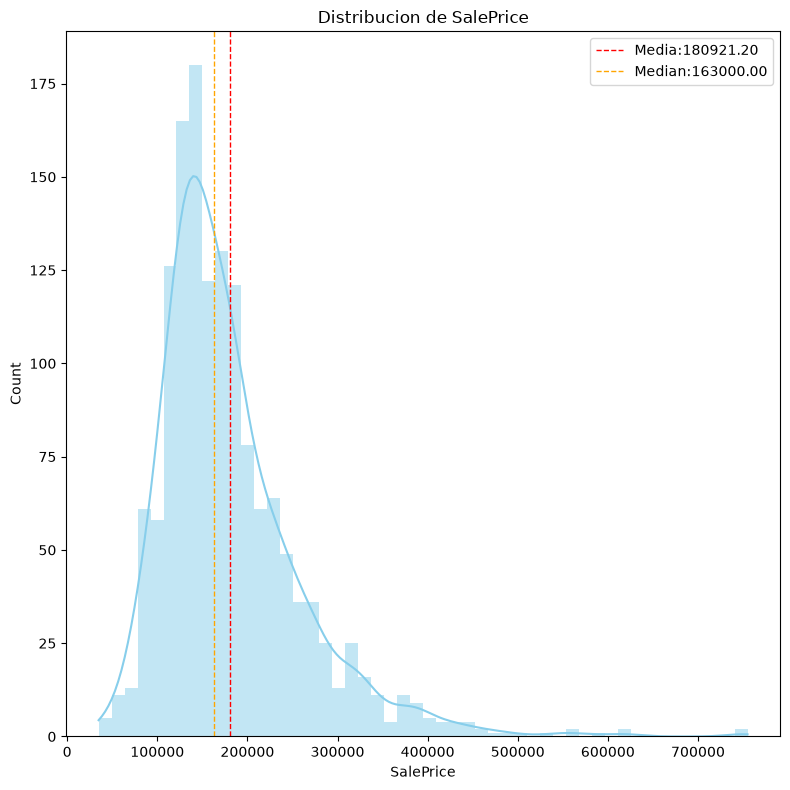

In [477]:
#Skewness and Distribution Plot

mean=df_hp['SalePrice'].mean()
median=df_hp['SalePrice'].median()

fig,ax=plt.subplots(figsize=(8,8))

sns.histplot(df_hp['SalePrice'],ax=ax,bins=50,kde=True,color='skyblue',linewidth=0)
ax.axvline(mean,color='red',linestyle='--',linewidth=1,label=f'Media:{mean:.2f}')
ax.axvline(median,color='orange',linestyle='--',linewidth=1,label=f'Median:{median:.2f}')

ax.set_title('Distribucion de SalePrice')
ax.legend()
fig.tight_layout()
plt.show()

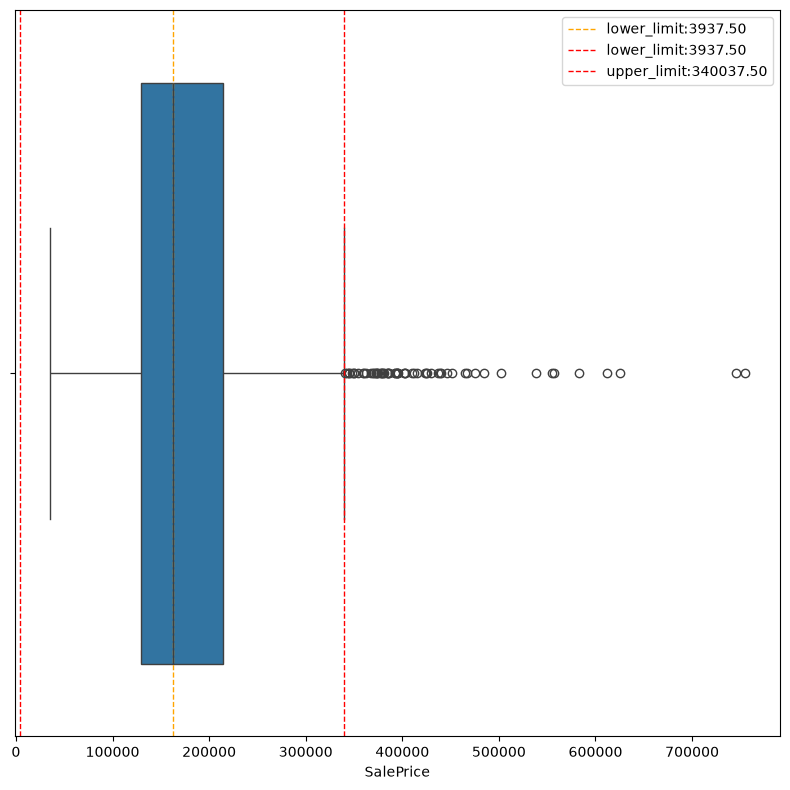

In [478]:
#Outliers

q1=df_hp['SalePrice'].quantile(.25)
q3=df_hp['SalePrice'].quantile(.75)

iqr=q3-q1

lower_limit=q1-(1.5*iqr)
upper_limit=q3+(1.5*iqr)

fig,ax=plt.subplots(figsize=(8,8))

sns.boxplot(data=df_hp,x='SalePrice',ax=ax)
ax.axvline(df_hp['SalePrice'].median(),color='orange',linestyle='--',linewidth=1,label=f'lower_limit:{lower_limit:.2f}')
ax.axvline(lower_limit,color='red',linestyle='--',linewidth=1,label=f'lower_limit:{lower_limit:.2f}')
ax.axvline(upper_limit,color='red',linestyle='--',linewidth=1,label=f'upper_limit:{upper_limit:.2f}')
ax.legend()

fig.tight_layout()
plt.show()

In [479]:
tracker.add_finding(
    var='SalePrice',
    stage='DU - Target Analysis - Distribution',
    finding=(
        'SalePrice shows strong positive skewness; '
        'a distribution transformation should be evaluated in DP.'
    )
)

tracker.add_finding(
    var='SalePrice',
    stage='DU - Target Analysis - Outliers',
    finding=(
        'Upper-tail observations exceed the IQR upper bound (~340,037.5); '
        'they require evaluation but should not be removed automatically.'
    )
)

17

In [480]:
tracker.save('tracking')

### DU_Feature_Analysis

Feature_Analysis
- Numeric variables vs target
- Categorical variables vs target
- Feature vs Feature (Multicollinearity)

In [481]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from data_tracker import DataTracker

In [482]:
df_hp=pd.read_csv('train.csv')
tracker = DataTracker.load(
    df_hp,
    path='tracking'
)
display(tracker.profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.000000,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,int64,nominal,15,0,0.000000,0.0,0.0,20.0,190.0,56.897260,50.0,42.300571,1.407657,1.580188
2,MSZoning,str,nominal,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,110,259,17.739726,0.0,0.0,21.0,313.0,70.049958,69.0,24.284752,2.163569,17.452867
4,LotArea,int64,continuous,1073,0,0.000000,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,temporal,12,0,0.000000,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,temporal,5,0,0.000000,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,nominal,9,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,nominal,6,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [483]:

# FEATURE ANALYSIS - NUMERIC VS TARGET


target = 'SalePrice'

numeric_cols = df_hp.select_dtypes(
    include='number'
).columns

correlation_num = (
    df_hp[numeric_cols]
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

display(correlation_num)

OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
ScreenPorch      0.111447
PoolArea         0.092404
MSSubClass      -0.084284
OverallCond     -0.077856
MoSold           0.046432
3SsnPorch        0.044584
YrSold          -0.028923
LowQualFinSF    -0.025606
Id              -0.021917
MiscVal         -0.021190
BsmtHalfBath    -0.016844
BsmtFinSF2      -0.011378
Name: SalePrice, dtype: float64

In [484]:
top_correlation_num = correlation_num[
    correlation_num.abs() > 0.5
]

display(top_correlation_num)

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

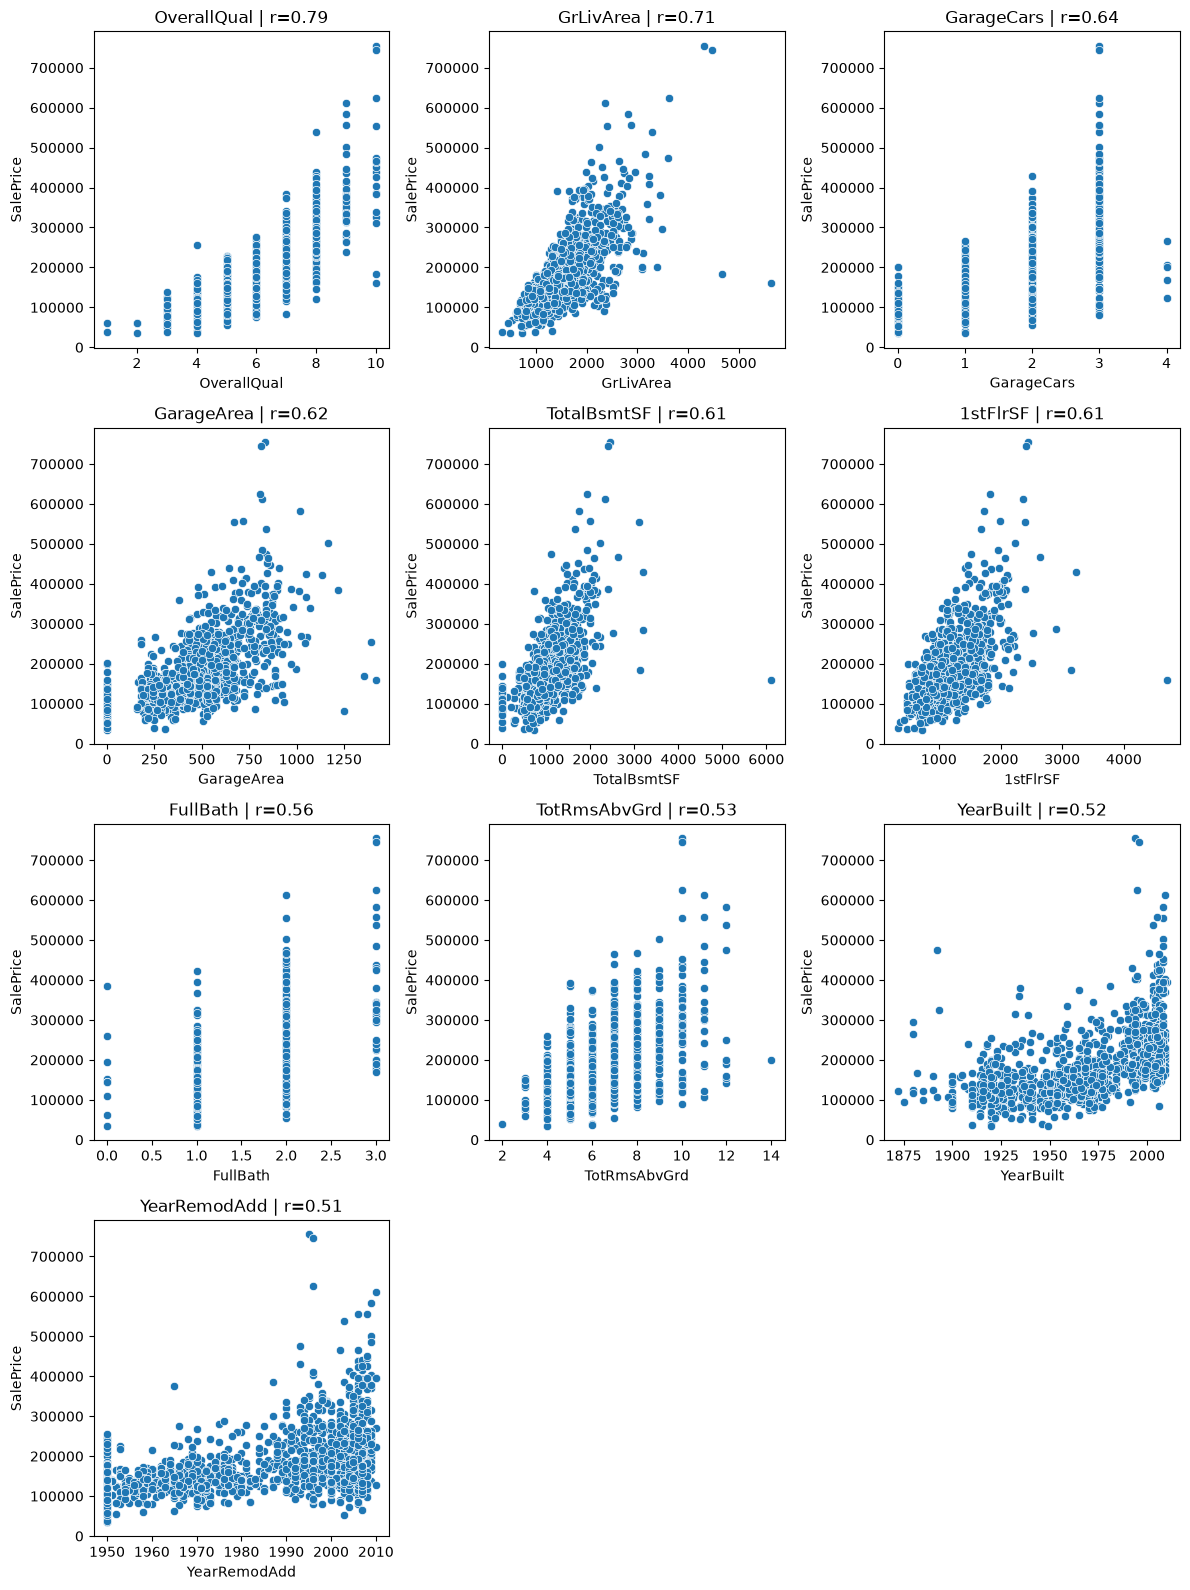

In [485]:
import math

n_cols = 3
n_rows = math.ceil(len(top_correlation_num) / n_cols)

fig, ax = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 4 * n_rows)
)

ax = np.array(ax).flatten()

for index, var in enumerate(top_correlation_num.index):

    sns.scatterplot(
        x=df_hp[var],
        y=df_hp[target],
        ax=ax[index]
    )

    ax[index].set_title(
        f'{var} | r={top_correlation_num[var]:.2f}'
    )

# Quitar ejes sobrantes
for index in range(len(top_correlation_num), len(ax)):
    ax[index].remove()

fig.tight_layout()
plt.show()

In [486]:
tracker.add_finding(
    var='GrLivArea',
    stage='DU - Feature Analysis - Numeric vs Target',
    finding=(
        'Strong positive relationship with SalePrice, with extreme '
        'high-area observations showing unusually low SalePrice; '
        'requires outlier review.'
    )
)

18

In [487]:
#Categorical variables vs target
#   -Group effect (Diferencias entre grupos)
#   -Strength of effect (Magnitud de las diferencias)
#   -Ordered patters (Patrones y jerarquias)
#   -Group outliers (Categorias atipicas)


# FEATURE ANALYSIS - CATEGORICAL VS TARGET


target = 'SalePrice'

categorical_vars = tracker.profile.loc[
    tracker.profile['variable_type'].isin(['nominal', 'ordinal']),
    'var'
].tolist()

min_group_pct = 0.01
threshold = int(len(df_hp) * min_group_pct)

categorical_analysis = []

for col in categorical_vars:

    g = (
        df_hp
        .groupby(col, observed=True)[target]
        .agg(['mean', 'median', 'count'])
    )

    n_total = len(df_hp)
    n_categories = g.shape[0]

    min_count = g['count'].min()
    max_count = g['count'].max()

    smallest_group_pct = min_count / n_total

    rare_groups_count = (
        g['count'] < threshold
    ).sum()

    imbalance_ratio = (
        max_count / max(1, min_count)
    )

    # Solo grupos con tamaño suficiente
    g_reliable = g[
        g['count'] >= threshold
    ]

    if g_reliable.empty:
        continue

    # ¿Media o mediana representa mejor los grupos?
    diff_rel = (
        (g_reliable['mean'] - g_reliable['median']).abs()
        / g_reliable['median']
    )

    score = diff_rel.median()

    measure = (
        'median'
        if score > 0.10
        else 'mean'
    )

    values = g_reliable[measure]

    effect = (
        values.max() - values.min()
    )

    categorical_analysis.append({
        'var': col,
        'n_categories': n_categories,
        'reliable_groups': len(g_reliable),
        'min_group_size': min_count,
        'min_group_pct': smallest_group_pct,
        'rare_groups_count': rare_groups_count,
        'imbalance_ratio': imbalance_ratio,
        'target_group_range': effect,
        'measure': measure
    })

categorical_analysis = (
    pd.DataFrame(categorical_analysis)
    .sort_values(
        'target_group_range',
        ascending=False
    )
)

display(categorical_analysis)

,var,n_categories,reliable_groups,min_group_size,min_group_pct,rare_groups_count,imbalance_ratio,target_group_range,measure
14,OverallQual,10,8,2,0.001370,2,198.500000,351114.638889,mean
21,ExterQual,4,4,14,0.009589,0,64.714286,279375.747253,mean
9,Neighborhood,25,22,2,0.001370,3,112.500000,236718.846485,mean
33,KitchenQual,4,4,39,0.026712,0,18.846154,222989.464872,mean
24,BsmtQual,4,4,35,0.023973,0,18.542857,211349.012751,mean
35,FireplaceQu,5,5,20,0.013699,0,19.000000,207948.350000,mean
0,MSSubClass,15,12,4,0.002740,3,134.000000,144118.777035,mean
43,SaleType,9,3,2,0.001370,6,633.500000,130972.162219,mean
18,Exterior1st,15,10,1,0.000685,5,515.000000,124305.105738,mean
36,GarageType,6,4,6,0.004110,2,145.000000,120660.575846,mean


In [488]:
reliable_comparison = categorical_analysis[
    categorical_analysis['reliable_groups'] >= 2
]

display(
    reliable_comparison.sort_values(
        'target_group_range',
        ascending=False
    )
)

,var,n_categories,reliable_groups,min_group_size,min_group_pct,rare_groups_count,imbalance_ratio,target_group_range,measure
14,OverallQual,10,8,2,0.001370,2,198.500000,351114.638889,mean
21,ExterQual,4,4,14,0.009589,0,64.714286,279375.747253,mean
9,Neighborhood,25,22,2,0.001370,3,112.500000,236718.846485,mean
33,KitchenQual,4,4,39,0.026712,0,18.846154,222989.464872,mean
24,BsmtQual,4,4,35,0.023973,0,18.542857,211349.012751,mean
35,FireplaceQu,5,5,20,0.013699,0,19.000000,207948.350000,mean
0,MSSubClass,15,12,4,0.002740,3,134.000000,144118.777035,mean
43,SaleType,9,3,2,0.001370,6,633.500000,130972.162219,mean
18,Exterior1st,15,10,1,0.000685,5,515.000000,124305.105738,mean
36,GarageType,6,4,6,0.004110,2,145.000000,120660.575846,mean


In [489]:

# FEATURE VS FEATURE - MULTICOLLINEARITY


target = 'SalePrice'
threshold = 0.7

numeric_features = (
    df_hp
    .select_dtypes(include='number')
    .drop(columns=[target])
)

corr_matrix = numeric_features.corr()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr = (
    upper
    .stack()
    .reset_index()
)

high_corr.columns = [
    'var1',
    'var2',
    'corr'
]

high_corr = (
    high_corr[
        high_corr['corr'].abs() >= threshold
    ]
    .sort_values(
        'corr',
        key=abs,
        ascending=False
    )
)

display(high_corr)

,var1,var2,corr
989,GarageCars,GarageArea,0.882475
247,YearBuilt,GarageYrBlt,0.825667
615,GrLivArea,TotRmsAbvGrd,0.825489
457,TotalBsmtSF,1stFlrSF,0.819530


In [490]:
for _, row in high_corr.iterrows():

    tracker.add_finding(
        var=f"{row['var1']} | {row['var2']}",
        stage='DU - Feature Analysis - Multicollinearity',
        finding=(
            f"High feature-to-feature correlation detected "
            f"(r={row['corr']:.3f}); potential redundancy "
            f"should be evaluated before modeling."
        )
    )

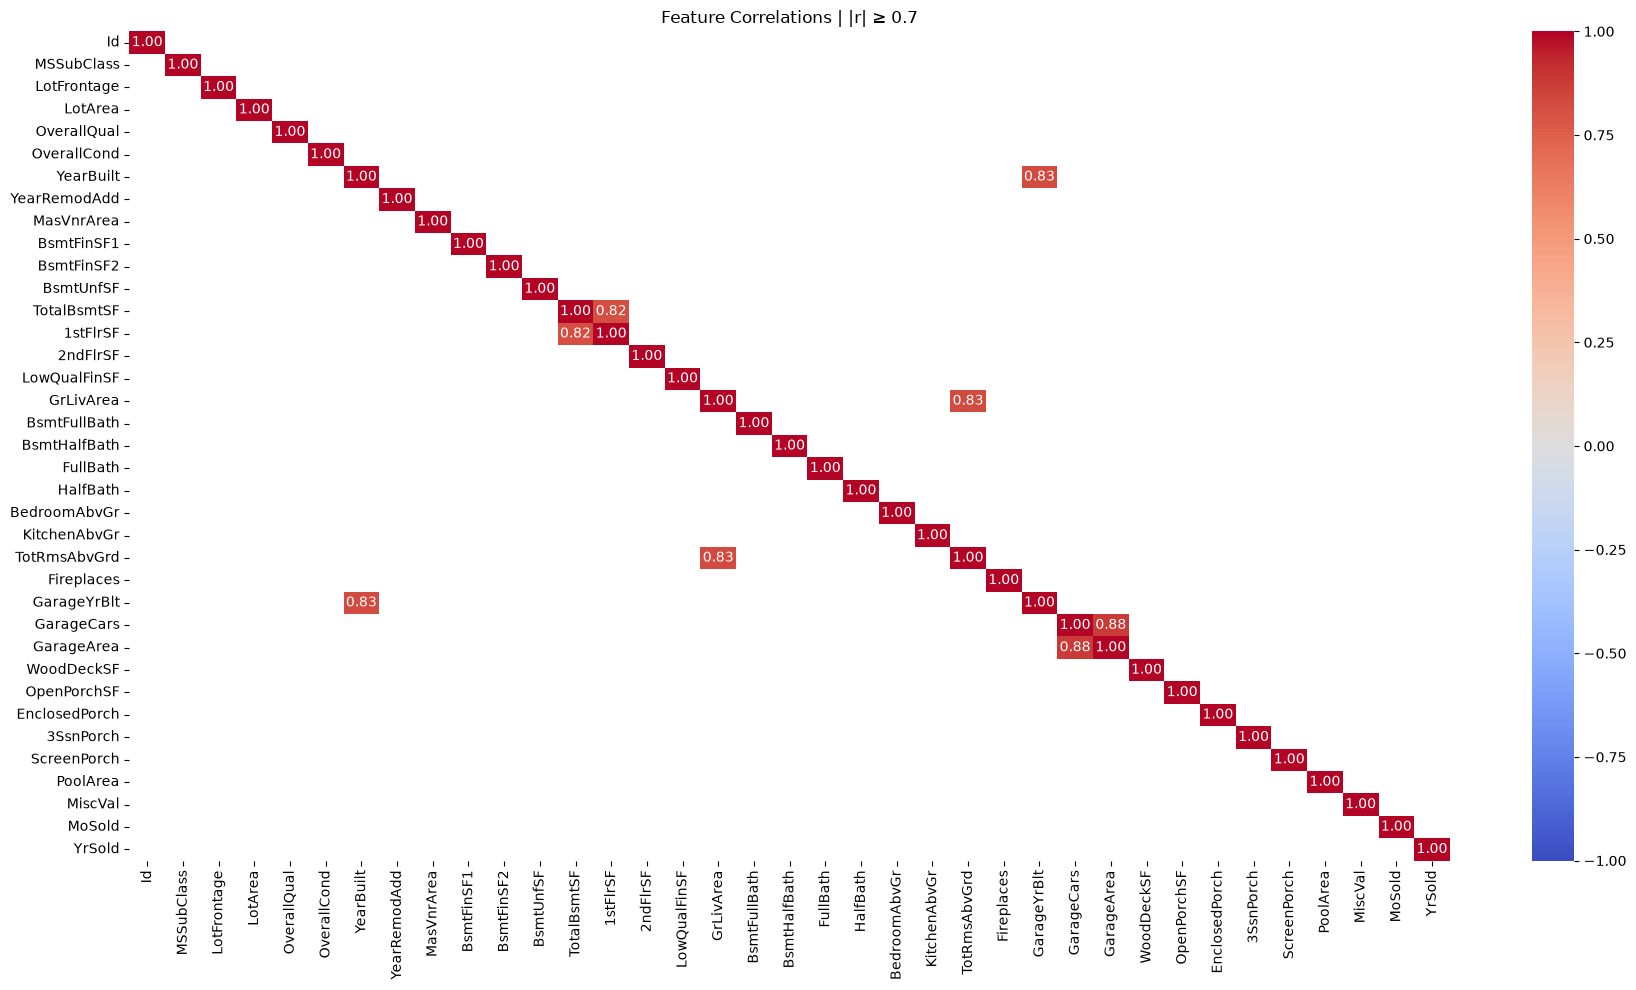

In [491]:

# MULTICOLLINEARITY - HEATMAP


mask = corr_matrix.abs() < threshold

# Ocultar diagonal
#np.fill_diagonal(mask.values, True)

fig, ax = plt.subplots(figsize=(18, 10))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    ax=ax,
    fmt='.2f',
    annot=True,
    mask=mask,
    vmin=-1,
    vmax=1
)

ax.set_title(
    f'Feature Correlations | |r| ≥ {threshold}'
)

fig.tight_layout()
plt.show()

In [492]:

# SAVE TRACKER

tracker.save('tracking')

## 3. Limpieza y preparación de datos

Los problemas identificados durante el análisis se registran y posteriormente
se resuelven durante Data Preparation, manteniendo trazabilidad de las
decisiones tomadas.

DATA PREPARATION
- **Structure**
- Missing Values
- Feature Engineer
- Transformations
- Outliers
- Feature Selection
- Scaling

### DP_Structure

DATA PREPARATION
- **Structure**
- Missing Values
- Feature Engineer
- Transformations
- Outliers
- Feature Selection
- Scaling

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from data_tracker import DataTracker

In [ ]:
df_hp=pd.read_csv('train.csv')
tracker = DataTracker.load(
    df_hp,
    path='tracking'
)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.000000,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,int64,nominal,15,0,0.000000,0.0,0.0,20.0,190.0,56.897260,50.0,42.300571,1.407657,1.580188
2,MSZoning,str,nominal,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,110,259,17.739726,0.0,0.0,21.0,313.0,70.049958,69.0,24.284752,2.163569,17.452867
4,LotArea,int64,continuous,1073,0,0.000000,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,temporal,12,0,0.000000,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,temporal,5,0,0.000000,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,nominal,9,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,nominal,6,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DATA PREPARATION

└── Structure 

    ─ Ajustar tipos físicos de datos

    ─ Corregir clasificaciones necesarias

    ─ Tratar variables temporales

    ─ Eliminar identificadores / columnas no utilizables

In [ ]:

# DP - STRUCTURE recuperamos los hallazgos


structure_pending = tracker.pending()

structure_pending = structure_pending[
    structure_pending['stage'].str.contains(
        'DU - Structure',
        case=False,
        na=False
    )
]

display(structure_pending)

,id,var,stage,finding,status,resolution
0,1,MSSubClass,DU - Structure,Nominal variable stored as numeric,pending,NaN


In [ ]:
# Estado anterior
before_dtype = str(df_hp['MSSubClass'].dtype)

# Transformación
df_hp['MSSubClass'] = df_hp['MSSubClass'].astype(str)

# Estado posterior
after_dtype = str(df_hp['MSSubClass'].dtype)

In [ ]:
tracker.log(
    var='MSSubClass',
    stage='DP - Structure',
    action='change_dtype',
    method='astype(str)',
    before=before_dtype,
    after=after_dtype
)

1

In [ ]:
tracker.resolve_finding(
    finding_id=1,
    resolution='Converted MSSubClass from numeric to string.'
)

In [ ]:

# SAVE TRACKER

df_hp.to_parquet(
    'processed/01_structure.parquet',
    index=False
)
tracker.save('tracking')

### DP_Missing_Values

DATA PREPARATION
- Structure
- **Missing Values**
- Feature Engineer
- Transformations
- Outliers
- Feature Selection
- Scaling

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from data_tracker import DataTracker

In [ ]:
df_hp = pd.read_parquet('processed/01_structure.parquet')
tracker = DataTracker.load(
    df_hp,
    path='tracking'
)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.000000,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,str,nominal,15,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,str,nominal,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,110,259,17.739726,0.0,0.0,21.0,313.0,70.049958,69.0,24.284752,2.163569,17.452867
4,LotArea,int64,continuous,1073,0,0.000000,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,temporal,12,0,0.000000,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,temporal,5,0,0.000000,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,nominal,9,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,nominal,6,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


MISSING VALUES
- Imputacion
- Crear categorias None
- Eliminar Columnas con muchos NAN
  

In [ ]:
def print_missing_findings():
    missing_findings = tracker.pending()

    missing_findings = missing_findings[
        missing_findings['stage'].eq(
            'DU - Quality - Missing Values'
        )
    ]
    display(missing_findings)

print_missing_findings()

,id,var,stage,finding,status,resolution
1,2,structural_missing_features,DU - Quality - Missing Values,"Structural missing values detected in: PoolQC,...",pending,NaN
2,3,LotFrontage,DU - Quality - Missing Values,17.74% missing. LotFrontage distribution varie...,pending,NaN
3,4,MasVnrType,DU - Quality - Missing Values,859 missing values coincide with MasVnrArea = ...,pending,NaN
5,6,MasVnrArea,DU - Quality - Missing Values,8 records have both MasVnrType and MasVnrArea ...,pending,NaN
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,pending,NaN


In [ ]:
structural_missing_features=tracker.findings[tracker.findings['var'].eq('structural_missing_features')]
display(structural_missing_features)

,id,var,stage,finding,status,resolution
1,2,structural_missing_features,DU - Quality - Missing Values,"Structural missing values detected in: PoolQC,...",pending,NaN


In [ ]:
structural_cat = [
    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'BsmtQual',
    'BsmtCond'
]
for col in structural_cat:

    before_missing = df_hp[col].isna().sum()

    df_hp[col] = df_hp[col].fillna('None')

    after_missing = df_hp[col].isna().sum()

    tracker.log(
        var=col,
        stage='DP - Missing Values',
        action='encode_structural_absence',
        method="fillna('None')",
        before=f'{before_missing} missing',
        after=f'{after_missing} missing'
    )

In [ ]:
tracker.resolve_finding(
    finding_id=structural_missing_features['id'].iloc[0],
    resolution=(
        "Structural categorical missing values were encoded as 'None'. "
        "GarageYrBlt missing values were preserved because absence of "
        "a garage has no meaningful construction year."
    )
)
display(tracker.findings[tracker.findings['var'].eq(structural_missing_features['var'].iloc[0])])
print_missing_findings()

,id,var,stage,finding,status,resolution
1,2,structural_missing_features,DU - Quality - Missing Values,"Structural missing values detected in: PoolQC,...",resolved,Structural categorical missing values were enc...


,id,var,stage,finding,status,resolution
2,3,LotFrontage,DU - Quality - Missing Values,17.74% missing. LotFrontage distribution varie...,pending,NaN
3,4,MasVnrType,DU - Quality - Missing Values,859 missing values coincide with MasVnrArea = ...,pending,NaN
5,6,MasVnrArea,DU - Quality - Missing Values,8 records have both MasVnrType and MasVnrArea ...,pending,NaN
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,pending,NaN


In [ ]:
LotFrontage=tracker.findings[tracker.findings['var'].eq('LotFrontage')]
display(LotFrontage)

,id,var,stage,finding,status,resolution
2,3,LotFrontage,DU - Quality - Missing Values,17.74% missing. LotFrontage distribution varie...,pending,NaN


In [ ]:

before_missing = df_hp['LotFrontage'].isna().sum()
display(before_missing)

neighborhood_median = (
    df_hp
    .groupby('Neighborhood')['LotFrontage']
    .transform('median')
)
display(neighborhood_median)

df_hp['LotFrontage'] = (
    df_hp['LotFrontage']
    .fillna(neighborhood_median)
)

np.int64(259)

0       70.0
1       68.0
2       70.0
3       74.0
4       91.0
        ... 
1455    65.0
1456    80.0
1457    74.0
1458    73.0
1459    65.5
Name: LotFrontage, Length: 1460, dtype: float64

In [ ]:
after_missing = df_hp['LotFrontage'].isna().sum()

print('Before:', before_missing)
print('After:', after_missing)

tracker.log(
    var='LotFrontage',
    stage='DP - Missing Values',
    action='impute',
    method='median_by_Neighborhood',
    before=f'{before_missing} missing',
    after=f'{after_missing} missing'
)
tracker.resolve_finding(
    finding_id=LotFrontage['id'].iloc[0],
    resolution=(
        'Missing LotFrontage values imputed using '
        'the median LotFrontage within each Neighborhood.'
    )
)

LotFrontage=tracker.findings[tracker.findings['var'].eq('LotFrontage')]
display(LotFrontage)
print_missing_findings()

Before: 259
After: 0


,id,var,stage,finding,status,resolution
2,3,LotFrontage,DU - Quality - Missing Values,17.74% missing. LotFrontage distribution varie...,resolved,Missing LotFrontage values imputed using the m...


,id,var,stage,finding,status,resolution
3,4,MasVnrType,DU - Quality - Missing Values,859 missing values coincide with MasVnrArea = ...,pending,NaN
5,6,MasVnrArea,DU - Quality - Missing Values,8 records have both MasVnrType and MasVnrArea ...,pending,NaN
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,pending,NaN


In [ ]:
MasVnrType = tracker.findings[
    (tracker.findings['var'] == 'MasVnrType') & 
    (tracker.findings['stage'] == 'DU - Quality - Missing Values')
]
display(MasVnrType)

,id,var,stage,finding,status,resolution
3,4,MasVnrType,DU - Quality - Missing Values,859 missing values coincide with MasVnrArea = ...,pending,NaN


In [ ]:

mask_no_veneer = (
    df_hp['MasVnrType'].isna() &
    df_hp['MasVnrArea'].eq(0)
)

display(mask_no_veneer.sum())

df_hp.loc[
    mask_no_veneer,
    'MasVnrType'
] = 'None'

df_hp.loc[
    df_hp['MasVnrArea'].eq(0),
    'MasVnrType'
].value_counts(dropna=False)

np.int64(859)

MasVnrType
None       859
BrkFace      1
Stone        1
Name: count, dtype: int64

In [ ]:
tracker.resolve_finding(
    finding_id=MasVnrType['id'].iloc[0],
    resolution=(
        "859 missing MasVnrType values with MasVnrArea = 0 "
        "were encoded as 'None'."
    )
)

tracker.log(
    var='MasVnrType',
    stage='DP - Missing Values',
    action='impute_structural_absence',
    method='None_when_MasVnrArea_equals_0',
    before='859 missing with MasVnrArea = 0',
    after='859 values encoded as None'
)

17

In [ ]:
MasVnrType = tracker.findings[
    (tracker.findings['var'] == 'MasVnrType') & 
    (tracker.findings['stage'] == 'DU - Quality - Missing Values')
]
display(MasVnrType)
print_missing_findings()

,id,var,stage,finding,status,resolution
3,4,MasVnrType,DU - Quality - Missing Values,859 missing values coincide with MasVnrArea = ...,resolved,859 missing MasVnrType values with MasVnrArea ...


,id,var,stage,finding,status,resolution
5,6,MasVnrArea,DU - Quality - Missing Values,8 records have both MasVnrType and MasVnrArea ...,pending,NaN
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,pending,NaN


In [ ]:
MasVnrArea = tracker.findings[
    (tracker.findings['var'] == 'MasVnrArea')
]
display(MasVnrArea)

,id,var,stage,finding,status,resolution
5,6,MasVnrArea,DU - Quality - Missing Values,8 records have both MasVnrType and MasVnrArea ...,pending,NaN


In [ ]:
mask_area_missing = df_hp['MasVnrArea'].isna()

display(
    df_hp.loc[
        mask_area_missing,
        ['MasVnrType', 'MasVnrArea']
    ]
)

print('MasVnrArea missing:', mask_area_missing.sum())

,MasVnrType,MasVnrArea
234,NaN,NaN
529,NaN,NaN
650,NaN,NaN
936,NaN,NaN
973,NaN,NaN
977,NaN,NaN
1243,NaN,NaN
1278,NaN,NaN


MasVnrArea missing: 8


In [ ]:
mask = (
    df_hp['MasVnrType'].isna() &
    df_hp['MasVnrArea'].isna()
)

df_hp.loc[mask, 'MasVnrType'] = 'None'
df_hp.loc[mask, 'MasVnrArea'] = 0

In [ ]:
print(df_hp['MasVnrArea'].isna().sum())
print(mask.sum())

0
8


In [ ]:
tracker.resolve_finding(
    finding_id=MasVnrArea['id'].iloc[0],
    resolution=(
        "8 records with both MasVnrType and MasVnrArea missing "
        "were treated as structural absence: "
        "MasVnrType='None' and MasVnrArea=0."
    )
)
tracker.log(
    var='MasVnrType',
    stage='DP - Missing Values',
    action='impute',
    method='assumed_structural_absence',
    before='8 missing',
    after="8 values encoded as 'None'"
)
MasVnrArea = tracker.findings[
    (tracker.findings['var'] == 'MasVnrArea')
]
display(MasVnrArea)
print_missing_findings()

,id,var,stage,finding,status,resolution
5,6,MasVnrArea,DU - Quality - Missing Values,8 records have both MasVnrType and MasVnrArea ...,resolved,8 records with both MasVnrType and MasVnrArea ...


,id,var,stage,finding,status,resolution
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,pending,NaN


In [ ]:
Electrical=tracker.findings[tracker.findings['var'].eq('Electrical')]
display(Electrical)

,id,var,stage,finding,status,resolution
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,pending,NaN


In [ ]:
electrical_mode = df_hp['Electrical'].mode()[0]

electrical_mode

'SBrkr'

In [ ]:
before_missing = df_hp['Electrical'].isna().sum()

df_hp['Electrical'] = (
    df_hp['Electrical']
    .fillna(electrical_mode)
)

after_missing = df_hp['Electrical'].isna().sum()

print('Before:', before_missing)
print('After:', after_missing)

Before: 1
After: 0


In [ ]:
tracker.resolve_finding(
    finding_id=Electrical['id'].iloc[0],
    resolution=(
        "1 missing Electrical value was imputed "
        "using the mode ('SBrkr')."
    )
)
tracker.log(
    var='Electrical',
    stage='DP - Missing Values',
    action='impute',
    method='mode',
    before='1 missing',
    after='0 missing'
)
Electrical=tracker.findings[tracker.findings['var'].eq('Electrical')]
display(Electrical)
print_missing_findings()

,id,var,stage,finding,status,resolution
6,7,Electrical,DU - Quality - Missing Values,1 missing value (0.07%). SBrkr is the dominant...,resolved,1 missing Electrical value was imputed using t...


,id,var,stage,finding,status,resolution


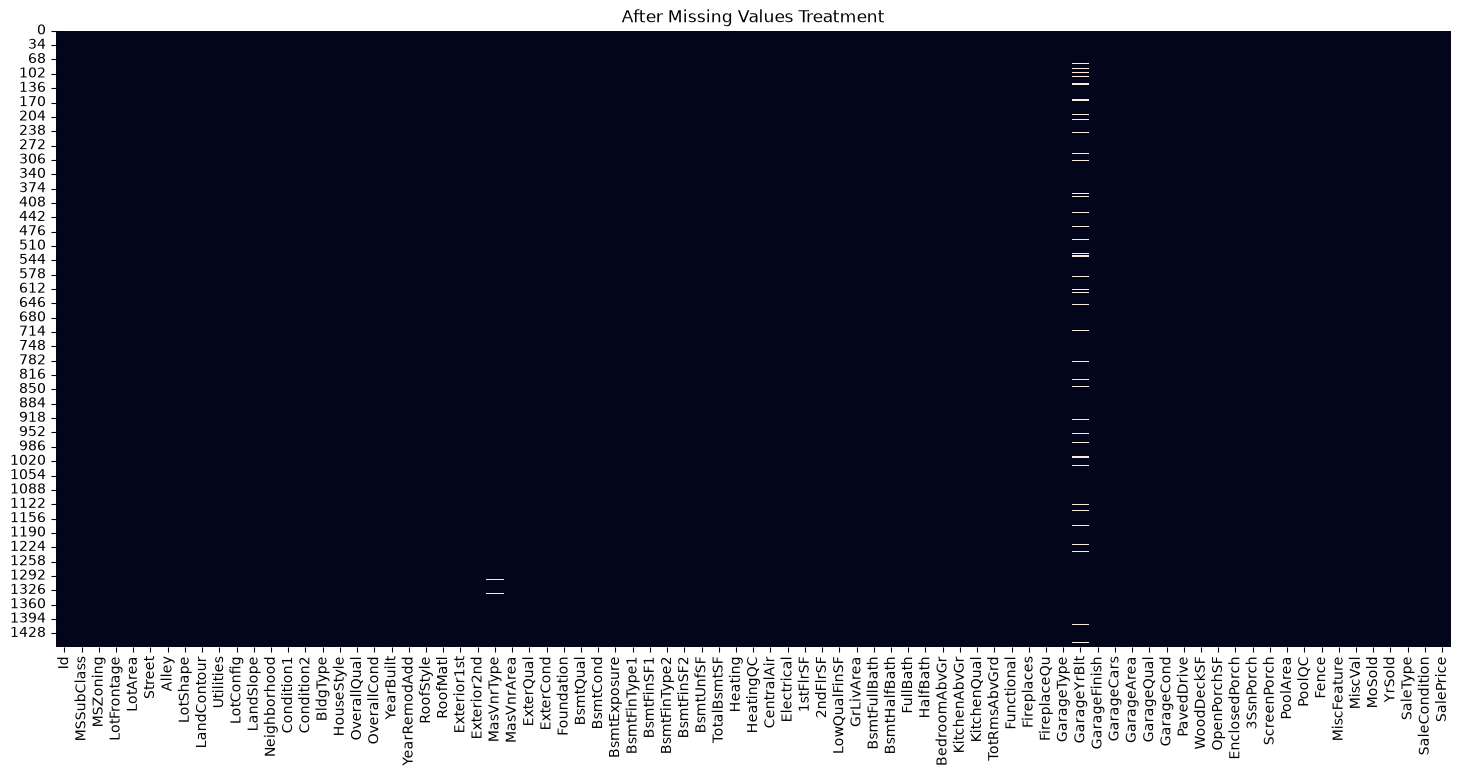

In [ ]:
plt.figure(figsize=(18, 8))

sns.heatmap(
    df_hp.isna(),
    cbar=False
)

plt.title("After Missing Values Treatment")

plt.show()

In [ ]:
remaining_missing = (
    df_hp.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

display(remaining_missing)

GarageYrBlt    81
MasVnrType      5
dtype: int64

In [ ]:
df_hp.loc[
    df_hp['GarageYrBlt'].isna(),
    ['GarageYrBlt', 'GarageType', 'GarageCars', 'GarageArea']
].value_counts(dropna=False)

GarageYrBlt  GarageType  GarageCars  GarageArea
NaN          None        0           0             81
Name: count, dtype: int64

In [ ]:
df_hp['GarageYrBlt'] = df_hp['GarageYrBlt'].fillna(0)

tracker.log(
    var='GarageYrBlt',
    stage='DP - Missing Values',
    action='impute',
    method='structural_zero',
    before='81 missing values',
    after='81 structural missing values filled with 0 (no garage)'
)

20

In [ ]:
df_hp['MasVnrType'] = df_hp['MasVnrType'].fillna('BrkFace')
tracker.log(
    var='MasVnrType',
    stage='DP - Missing Values',
    action='impute',
    method='conditional_mode',
    before='5 missing values with MasVnrArea > 0',
    after='5 missing values filled with BrkFace'
)
tracker.resolve_finding(
    5,
    resolution=(
        'Resolved by imputing the 5 missing MasVnrType values '
        'with BrkFace, the dominant category among observations '
        'with MasVnrArea > 0.'
    )
)

In [ ]:

# SAVE TRACKER

df_hp.to_parquet(
    'processed/02_missing_values.parquet',
    index=False
)
tracker.save('tracking')

### DP_Feature_Engineer

DATA PREPARATION
- Structure
- Missing Values
- **Feature Engineer**
- Transformations
- Outliers
- Feature Selection
- Scaling

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from data_tracker import DataTracker

In [ ]:
df_hp = pd.read_parquet('processed/02_missing_values.parquet')
tracker = DataTracker.load(
    df_hp,
    path='tracking'
)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.0,0.0,0.0,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,str,nominal,15,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,str,nominal,5,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,115,0,0.0,0.0,0.0,21.0,313.0,70.199658,70.0,22.431902,2.212959,20.099108
4,LotArea,int64,continuous,1073,0,0.0,0.0,0.0,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,MoSold,int64,temporal,12,0,0.0,0.0,0.0,1.0,12.0,6.321918,6.0,2.703626,0.212053,-0.404109
77,YrSold,int64,temporal,5,0,0.0,0.0,0.0,2006.0,2010.0,2007.815753,2008.0,1.328095,0.096269,-1.190601
78,SaleType,str,nominal,9,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,SaleCondition,str,nominal,6,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


FEATURE ENGINEER
- Temporal Features
- Aggregate Features
- Presence / Binary Features
- Interaction Features

In [ ]:
# TEMPORAL FEATURES

df_hp['HouseAge'] = (
    df_hp['YrSold'] - df_hp['YearBuilt']
)

df_hp['RemodAge'] = (
    df_hp['YrSold'] - df_hp['YearRemodAdd']
)

df_hp['GarageAge'] = np.where(
    df_hp['GarageYrBlt'] == 0,
    0,
    df_hp['YrSold'] - df_hp['GarageYrBlt']
)

In [ ]:
display(
    df_hp[
        [
            'YearBuilt',
            'YearRemodAdd',
            'GarageYrBlt',
            'YrSold',
            'HouseAge',
            'RemodAge',
            'GarageAge'
        ]
    ].describe()
)

,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold,HouseAge,RemodAge,GarageAge
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,1971.267808,1984.865753,1868.739726,2007.815753,36.547945,22.950000,27.680137
std,30.202904,20.645407,453.697295,1.328095,30.250152,20.640653,24.950144
min,1872.000000,1950.000000,0.000000,2006.000000,0.000000,-1.000000,0.000000
25%,1954.000000,1967.000000,1958.000000,2007.000000,8.000000,4.000000,4.000000
50%,1973.000000,1994.000000,1977.000000,2008.000000,35.000000,14.000000,23.500000
75%,2000.000000,2004.000000,2001.000000,2009.000000,54.000000,41.000000,46.000000
max,2010.000000,2010.000000,2010.000000,2010.000000,136.000000,60.000000,107.000000


In [ ]:
display(
    df_hp.loc[
        df_hp['RemodAge'] < 0,
        [
            'YearBuilt',
            'YearRemodAdd',
            'YrSold',
            'HouseAge',
            'RemodAge'
        ]
    ]
)

,YearBuilt,YearRemodAdd,YrSold,HouseAge,RemodAge
523,2007,2008,2007,0,-1


In [ ]:
tracker.add_finding(
    var='YearRemodAdd | YrSold',
    stage='DP - Feature Engineering - Temporal',
    finding=(
        '1 record has YearRemodAdd > YrSold '
        '(index 523: YearRemodAdd=2008, YrSold=2007), '
        'producing RemodAge=-1.'
    )
)

23

In [ ]:
df_hp['RemodAge'] = (
    df_hp['YrSold'] - df_hp['YearRemodAdd']
).clip(lower=0)

tracker.log(
    var='RemodAge',
    stage='DP - Feature Engineering - Temporal',
    action='create_feature',
    method='year_difference_clipped',
    before='1 record produced RemodAge=-1',
    after='RemodAge minimum constrained to 0'
)
tracker.resolve_finding(
    23,
    resolution=(
        'Resolved by constraining RemodAge to a minimum of 0; '
        'the inconsistent record was assigned RemodAge=0.'
    )
)

In [ ]:
tracker.log(
    var='HouseAge',
    stage='DP - Feature Engineering',
    action='create_feature',
    method='YrSold - YearBuilt',
    before='YrSold, YearBuilt',
    after='HouseAge'
)

tracker.log(
    var='RemodAge',
    stage='DP - Feature Engineering',
    action='create_feature',
    method='YrSold - YearRemodAdd',
    before='YrSold, YearRemodAdd',
    after='RemodAge'
)

tracker.log(
    var='GarageAge',
    stage='DP - Feature Engineering',
    action='create_feature',
    method='YrSold - GarageYrBlt',
    before='YrSold, GarageYrBlt',
    after='GarageAge'
)

25

In [ ]:
#Aggregate Features

df_hp['TotalSF'] = (
    df_hp['TotalBsmtSF']
    + df_hp['GrLivArea']
)

df_hp['TotalBathrooms'] = (
    df_hp['FullBath']
    + 0.5 * df_hp['HalfBath']
    + df_hp['BsmtFullBath']
    + 0.5 * df_hp['BsmtHalfBath']
)

df_hp['TotalPorchSF'] = (
    df_hp['WoodDeckSF']
    + df_hp['OpenPorchSF']
    + df_hp['EnclosedPorch']
    + df_hp['3SsnPorch']
    + df_hp['ScreenPorch']
)

In [ ]:
display(
    df_hp[
        [
            'TotalSF',
            'TotalBathrooms',
            'TotalPorchSF'
        ]
    ].describe()
)

,TotalSF,TotalBathrooms,TotalPorchSF
count,1460.000000,1460.000000,1460.000000
mean,2572.893151,2.210616,181.329452
std,823.598492,0.785399,156.656097
min,334.000000,1.000000,0.000000
25%,2014.000000,2.000000,45.000000
50%,2479.000000,2.000000,164.000000
75%,3008.500000,2.500000,266.000000
max,11752.000000,6.000000,1027.000000


In [ ]:
tracker.log(
    var='TotalSF',
    stage='DP - Feature Engineering',
    action='create_feature',
    method='TotalBsmtSF + GrLivArea',
    before='TotalBsmtSF, GrLivArea',
    after='TotalSF'
)

tracker.log(
    var='TotalBathrooms',
    stage='DP - Feature Engineering',
    action='create_feature',
    method='FullBath + 0.5*HalfBath + BsmtFullBath + 0.5*BsmtHalfBath',
    before='FullBath, HalfBath, BsmtFullBath, BsmtHalfBath',
    after='TotalBathrooms'
)

tracker.log(
    var='TotalPorchSF',
    stage='DP - Feature Engineering',
    action='create_feature',
    method='WoodDeckSF + OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch',
    before='WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch',
    after='TotalPorchSF'
)

28

In [ ]:
# PRESENCE / BINARY FEATURES

df_hp['HasGarage'] = (
    df_hp['GarageArea'] > 0
).astype(int)

df_hp['HasBasement'] = (
    df_hp['TotalBsmtSF'] > 0
).astype(int)

df_hp['HasPool'] = (
    df_hp['PoolArea'] > 0
).astype(int)

df_hp['HasFireplace'] = (
    df_hp['Fireplaces'] > 0
).astype(int)

df_hp['IsRemodeled'] = (
    df_hp['YearBuilt'] != df_hp['YearRemodAdd']
).astype(int)

In [ ]:
binary_features = [
    'HasGarage',
    'HasBasement',
    'HasPool',
    'HasFireplace',
    'IsRemodeled'
]

for col in binary_features:
    print(f'\n{col}')
    print(df_hp[col].value_counts())

for col in binary_features:
    print(
        col,
        sorted(df_hp[col].unique())
    )


HasGarage
HasGarage
1    1379
0      81
Name: count, dtype: int64

HasBasement
HasBasement
1    1423
0      37
Name: count, dtype: int64

HasPool
HasPool
0    1453
1       7
Name: count, dtype: int64

HasFireplace
HasFireplace
1    770
0    690
Name: count, dtype: int64

IsRemodeled
IsRemodeled
0    764
1    696
Name: count, dtype: int64
HasGarage [np.int64(0), np.int64(1)]
HasBasement [np.int64(0), np.int64(1)]
HasPool [np.int64(0), np.int64(1)]
HasFireplace [np.int64(0), np.int64(1)]
IsRemodeled [np.int64(0), np.int64(1)]


In [ ]:
binary_methods = {
    'HasGarage': 'GarageArea > 0',
    'HasBasement': 'TotalBsmtSF > 0',
    'HasPool': 'PoolArea > 0',
    'HasFireplace': 'Fireplaces > 0',
    'IsRemodeled': 'YearBuilt != YearRemodAdd'
}

for var, method in binary_methods.items():

    tracker.log(
        var=var,
        stage='DP - Feature Engineering',
        action='create_binary_feature',
        method=method,
        before='source variable(s)',
        after=var
    )

In [ ]:
# INTERACTION FEATURES
# Captura la interacción entre calidad general y superficie habitable

df_hp['QualGrLivArea'] = (
    df_hp['OverallQual']
    * df_hp['GrLivArea']
)

display(
    df_hp[
        [
            'OverallQual',
            'GrLivArea',
            'QualGrLivArea'
        ]
    ].describe()
)

,OverallQual,GrLivArea,QualGrLivArea
count,1460.000000,1460.000000,1460.000000
mean,6.099315,1515.463699,9673.956164
std,1.382997,525.480383,5186.744876
min,1.000000,334.000000,334.000000
25%,5.000000,1129.500000,5790.000000
50%,6.000000,1464.000000,8820.000000
75%,7.000000,1776.750000,12180.000000
max,10.000000,5642.000000,56420.000000


In [ ]:
df_hp[[
        'OverallQual',
        'GrLivArea',
        'QualGrLivArea',
        'SalePrice'
]
].corr()['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
QualGrLivArea    0.832057
OverallQual      0.790982
GrLivArea        0.708624
Name: SalePrice, dtype: float64

In [ ]:
tracker.log(
    var='QualGrLivArea',
    stage='DP - Feature Engineering',
    action='create_interaction_feature',
    method='OverallQual * GrLivArea',
    before='OverallQual, GrLivArea',
    after='QualGrLivArea'
)

34

In [ ]:

df_hp.to_parquet(
    'processed/03_feature_engineering.parquet',
    index=False
)
tracker.save('tracking')

### DP_Transformations

DATA PREPARATION
- Structure
- Missing Values
- Feature Engineer
- **Transformations**
- Outliers
- Feature Selection
- Scaling

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.stats import boxcox, yeojohnson
from data_tracker import DataTracker

In [ ]:
df_hp = pd.read_parquet('processed/03_feature_engineering.parquet')
tracker = DataTracker.load(
    df_hp,
    path='tracking'
)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.0,0.0,0.000000,1.0,1460.0,730.500000,730.5,421.610009,0.000000,-1.200000
1,MSSubClass,str,nominal,15,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,str,nominal,5,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,115,0,0.0,0.0,0.000000,21.0,313.0,70.199658,70.0,22.431902,2.212959,20.099108
4,LotArea,int64,continuous,1073,0,0.0,0.0,0.000000,1300.0,215245.0,10516.828082,9478.5,9981.264932,12.207688,203.243271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,HasBasement,int64,NaN,2,0,0.0,37.0,2.534247,0.0,1.0,0.974658,1.0,0.157217,-6.046534,34.607975
89,HasPool,int64,NaN,2,0,0.0,1453.0,99.520548,0.0,1.0,0.004795,0.0,0.069100,14.352680,204.279269
90,HasFireplace,int64,NaN,2,0,0.0,690.0,47.260274,0.0,1.0,0.527397,1.0,0.499420,-0.109867,-1.990658
91,IsRemodeled,int64,NaN,2,0,0.0,764.0,52.328767,0.0,1.0,0.476712,0.0,0.499629,0.093348,-1.994020


TRANSFORMATIONS
- **Distribution Transformations**
- Encoding
- Binning

In [ ]:
# Distribution Transformations

distribution_analysis = profile.loc[
    profile['variable_type'].isin([
        'continuous',
        'discrete'
    ]),
    [
        'var',
        'skewness',
        'kurtosis',
        'min',
        'max',
        'zero_count',
        'zero_pct'
    ]
].copy()

display(distribution_analysis.sort_values('skewness',ascending=False))

,var,skewness,kurtosis,min,max,zero_count,zero_pct
75,MiscVal,24.476794,701.003342,0.0,15500.0,1408.0,96.438356
71,PoolArea,14.828374,223.268499,0.0,738.0,1453.0,99.520548
4,LotArea,12.207688,203.243271,1300.0,215245.0,0.0,0.000000
69,3SsnPorch,10.304342,123.662379,0.0,508.0,1436.0,98.356164
45,LowQualFinSF,9.011341,83.234817,0.0,572.0,1434.0,98.219178
52,KitchenAbvGr,4.488397,21.532404,0.0,3.0,1.0,0.068493
36,BsmtFinSF2,4.255261,20.113338,0.0,1474.0,1293.0,88.561644
70,ScreenPorch,4.122214,18.439068,0.0,480.0,1344.0,92.054795
48,BsmtHalfBath,4.103403,16.396642,0.0,2.0,1378.0,94.383562
68,EnclosedPorch,3.089872,10.430766,0.0,552.0,1252.0,85.753425


In [ ]:
distribution_candidates = [
    'LotArea',
    'LotFrontage',
    'SalePrice',
    '1stFlrSF',
    'GrLivArea'
]

# Evaluar transformaciones sin modificar df_hp
evaluation = []

for var in distribution_candidates:

    x = df_hp[var].dropna()

    # Transformaciones
    x_log = np.log(x)
    x_sqrt = np.sqrt(x)

    x_boxcox, lambda_bc = boxcox(x)
    x_yj, lambda_yj = yeojohnson(x)

    evaluation.append({
        'var': var,

        'original_skew': x.skew(),

        'log_skew': pd.Series(x_log).skew(),
        'sqrt_skew': pd.Series(x_sqrt).skew(),

        'boxcox_skew': pd.Series(x_boxcox).skew(),
        'boxcox_lambda': lambda_bc,

        'yeojohnson_skew': pd.Series(x_yj).skew(),
        'yeojohnson_lambda': lambda_yj
    })

transformation_comparison = pd.DataFrame(evaluation)

display(transformation_comparison)

,var,original_skew,log_skew,sqrt_skew,boxcox_skew,boxcox_lambda,yeojohnson_skew,yeojohnson_lambda
0,LotArea,12.207688,-0.137994,4.139714,0.026687,0.030946,0.026569,0.030819
1,LotFrontage,2.212959,-0.945863,0.281391,0.178496,0.464319,0.171200,0.453941
2,SalePrice,1.882876,0.121335,0.943153,-0.008653,-0.076924,-0.008654,-0.076932
3,1stFlrSF,1.376757,0.079157,0.624263,-0.001098,-0.078832,-0.001106,-0.079877
4,GrLivArea,1.366560,-0.006995,0.594255,0.000195,0.006305,0.000171,0.005540


In [ ]:
transformations = {
    'LotArea': 'log',
    'LotFrontage': 'sqrt',
    'SalePrice': 'log',
    '1stFlrSF': 'log',
    'GrLivArea': 'log'
}

for var, method in transformations.items():

    if method == 'log':
        df_hp[var] = np.log(df_hp[var])

    elif method == 'sqrt':
        df_hp[var] = np.sqrt(df_hp[var])

In [ ]:
validation = []

for var, method in transformations.items():

    validation.append({
        'var': var,
        'method': method,
        'skew_after': df_hp[var].skew(),
        'kurt_after': df_hp[var].kurtosis(),
        'missing_after': df_hp[var].isna().sum()
    })

display(pd.DataFrame(validation))

,var,method,skew_after,kurt_after,missing_after
0,LotArea,log,-0.137994,4.713358,0
1,LotFrontage,sqrt,0.281391,4.993690,0
2,SalePrice,log,0.121335,0.809532,0
3,1stFlrSF,log,0.079157,0.150808,0
4,GrLivArea,log,-0.006995,0.282603,0


In [ ]:
for var, method in transformations.items():

    tracker.log(
        var=var,
        stage='DP - Transformations - Distribution',
        action='transform_distribution',
        method=method,
        before='original distribution',
        after=f'{method} transformed'
    )

In [ ]:

zero_magnitude_candidates = [
    'MasVnrArea',
    'BsmtFinSF1',
    'TotalBsmtSF',
    'WoodDeckSF',
    'OpenPorchSF'
]
zero_evaluation = []

for var in zero_magnitude_candidates:

    x = df_hp[var]
    transformed = np.log1p(x)

    zero_evaluation.append({
        'var': var,
        'zero_pct': (x == 0).mean() * 100,
        'skew_before': x.skew(),
        'skew_log1p': transformed.skew(),
        'kurt_before': x.kurtosis(),
        'kurt_log1p': transformed.kurtosis()
    })

zero_evaluation = pd.DataFrame(zero_evaluation)

display(zero_evaluation)

,var,zero_pct,skew_before,skew_log1p,kurt_before,kurt_log1p
0,MasVnrArea,59.520548,2.677616,0.503532,10.141416,-1.620317
1,BsmtFinSF1,31.986301,1.685503,-0.618410,11.118236,-1.476786
2,TotalBsmtSF,2.534247,1.524255,-5.154670,13.250483,27.739670
3,WoodDeckSF,52.123288,1.541376,0.153537,2.992951,-1.897931
4,OpenPorchSF,44.931507,2.364342,-0.023397,8.490336,-1.776583


In [ ]:
log1p_vars = [
    'MasVnrArea',
    'BsmtFinSF1',
    'WoodDeckSF',
    'OpenPorchSF'
]

for var in log1p_vars:
    df_hp[var] = np.log1p(df_hp[var])

df_hp[log1p_vars].skew()

MasVnrArea     0.503532
BsmtFinSF1    -0.618410
WoodDeckSF     0.153537
OpenPorchSF   -0.023397
dtype: float64

In [ ]:
for var in log1p_vars:

    tracker.log(
        var=var,
        stage='DP - Transformations - Distribution',
        action='transform_distribution',
        method='log1p',
        before='original distribution',
        after='log1p transformed'
    )

In [ ]:
# ENCODING

nominal_vars = profile.loc[
    profile['variable_type'].eq('nominal'),
    'var'
].tolist()

ordinal_vars = profile.loc[
    profile['variable_type'].eq('ordinal'),
    'var'
].tolist()


nominal_vars = [
    var for var in nominal_vars
    if var in df_hp.columns
]

ordinal_vars = [
    var for var in ordinal_vars
    if var in df_hp.columns
]

print('Nominal:', len(nominal_vars))
print('Ordinal:', len(ordinal_vars))

Nominal: 23
Ordinal: 23


In [ ]:
nominal_analysis = profile.loc[
    profile['var'].isin(nominal_vars),
    [
        'var',
        'unique_count'
    ]
].sort_values(
    'unique_count',
    ascending=False
)

display(nominal_analysis)

,var,unique_count
12,Neighborhood,25
24,Exterior2nd,16
1,MSSubClass,15
23,Exterior1st,15
13,Condition1,9
78,SaleType,9
22,RoofMatl,8
14,Condition2,8
16,HouseStyle,8
58,GarageType,7


In [ ]:
for var in nominal_vars:

    tracker.add_plan(
        var=var,
        stage='DP - Encoding',
        action='encode',
        method='onehot',
        params={
            'drop': None,
            'handle_unknown': 'ignore'
        }
    )

In [ ]:
# ordinal
ordinal_analysis = profile.loc[
    profile['var'].isin(ordinal_vars),
    [
        'var',
        'variable_type',
        'unique_count'
    ]
].copy()

display(ordinal_analysis)

,var,variable_type,unique_count
7,LotShape,ordinal,4
9,Utilities,ordinal,2
11,LandSlope,ordinal,3
17,OverallQual,ordinal,10
18,OverallCond,ordinal,9
27,ExterQual,ordinal,4
28,ExterCond,ordinal,5
30,BsmtQual,ordinal,5
31,BsmtCond,ordinal,5
32,BsmtExposure,ordinal,5


In [ ]:
for var in ordinal_vars:
    print(var, df_hp[var].dropna().unique())

LotShape <ArrowStringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str
Utilities <ArrowStringArray>
['AllPub', 'NoSeWa']
Length: 2, dtype: str
LandSlope <ArrowStringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str
OverallQual [ 7  6  8  5  9  4 10  3  1  2]
OverallCond [5 8 6 7 4 2 3 9 1]
ExterQual <ArrowStringArray>
['Gd', 'TA', 'Ex', 'Fa']
Length: 4, dtype: str
ExterCond <ArrowStringArray>
['TA', 'Gd', 'Fa', 'Po', 'Ex']
Length: 5, dtype: str
BsmtQual <ArrowStringArray>
['Gd', 'TA', 'Ex', 'None', 'Fa']
Length: 5, dtype: str
BsmtCond <ArrowStringArray>
['TA', 'Gd', 'None', 'Fa', 'Po']
Length: 5, dtype: str
BsmtExposure <ArrowStringArray>
['No', 'Gd', 'Mn', 'Av', 'None']
Length: 5, dtype: str
BsmtFinType1 <ArrowStringArray>
['GLQ', 'ALQ', 'Unf', 'Rec', 'BLQ', 'None', 'LwQ']
Length: 7, dtype: str
BsmtFinType2 <ArrowStringArray>
['Unf', 'BLQ', 'None', 'ALQ', 'Rec', 'LwQ', 'GLQ']
Length: 7, dtype: str
HeatingQC <ArrowStringArray>
['Ex', 'Gd', 'TA', 'Fa', 'Po']
Length: 5, dtype: s

In [ ]:
ordinal_orders = {

    'LotShape': ['IR3', 'IR2', 'IR1', 'Reg'],

    'Utilities': ['NoSeWa', 'AllPub'],

    'LandSlope': ['Sev', 'Mod', 'Gtl'],

    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'ExterCond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],

    'BsmtQual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtCond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],

    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],

    'HeatingQC': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],

    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1','Mod', 'Min2', 'Min1', 'Typ'],

    'FireplaceQu': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],

    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
    'GarageQual': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageCond': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],

    'PavedDrive': ['N', 'P', 'Y'],

    'PoolQC': ['None', 'Fa', 'TA', 'Gd', 'Ex']
}

In [ ]:
#se corrige el tipo de dato ya que analizando no es de tipo ordinal
profile.loc[
    profile['var'].isin(['Electrical', 'Fence']),
    'variable_type'
] = 'nominal'

display(
    profile.loc[
        profile['var'].isin(['Electrical', 'Fence']),
        ['var', 'data_type', 'variable_type']
    ]
)

,var,data_type,variable_type
42,Electrical,str,nominal
73,Fence,str,nominal


In [ ]:
for var, categories in ordinal_orders.items():

    tracker.add_plan(
        var=var,
        stage='DP - Encoding',
        action='encode',
        method='ordinal',
        params={
            'categories': categories
        }
    )

In [ ]:
display(
    tracker.plans[
        tracker.plans['stage'].eq('DP - Encoding')
    ]
)

,id,var,stage,action,method,params,status
0,1,MSSubClass,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
1,2,MSZoning,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
2,3,Street,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
3,4,Alley,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
4,5,LandContour,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
5,6,LotConfig,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
6,7,Neighborhood,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
7,8,Condition1,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
8,9,Condition2,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned
9,10,BldgType,DP - Encoding,encode,onehot,"{'drop': None, 'handle_unknown': 'ignore'}",planned


In [ ]:
nominal_vars = tracker.profile.loc[
    tracker.profile['variable_type'].eq('nominal'),
    'var'
].tolist()

ordinal_vars = tracker.profile.loc[
    tracker.profile['variable_type'].eq('ordinal'),
    'var'
].tolist()

print('Nominal:', len(nominal_vars))
print('Ordinal:', len(ordinal_vars))

Nominal: 25
Ordinal: 21


In [ ]:
print('Electrical' in nominal_vars)
print('Fence' in nominal_vars)

print('Electrical' in ordinal_vars)
print('Fence' in ordinal_vars)

True
True
False
False


In [ ]:
for var in ['Electrical', 'Fence']:
    tracker.add_plan(
        var=var,
        stage='DP - Encoding',
        action='encode',
        method='onehot',
        params={}
    )

In [ ]:
# BINNING

numeric_analysis = tracker.profile.loc[
    tracker.profile['variable_type'].isin([
        'continuous',
        'discrete'
    ]),
    [
        'var',
        'variable_type',
        'unique_count',
        'min',
        'max'
    ]
].copy()

display(
    numeric_analysis.sort_values(
        'unique_count',
        ascending=True
    )
)

#Binning → evaluado, no aplicado.

,var,variable_type,unique_count,min,max
48,BsmtHalfBath,discrete,3,0.0,2.0
50,HalfBath,discrete,3,0.0,2.0
49,FullBath,discrete,4,0.0,3.0
47,BsmtFullBath,discrete,4,0.0,3.0
56,Fireplaces,discrete,4,0.0,3.0
52,KitchenAbvGr,discrete,4,0.0,3.0
61,GarageCars,discrete,5,0.0,4.0
51,BedroomAbvGr,discrete,8,0.0,8.0
71,PoolArea,continuous,8,0.0,738.0
54,TotRmsAbvGrd,discrete,12,2.0,14.0


In [ ]:
tracker.resolve_finding(
    16,
    resolution=(
        'Resolved in DP - Transformations - Distribution. '
        'A log1p transformation was applied to SalePrice '
        'to reduce positive skewness.'
    )
)

In [ ]:

df_hp.to_parquet(
    'processed/04_transformations.parquet',
    index=False
)
tracker.save()

### DP_Outliers

DATA PREPARATION
- Structure
- Missing Values
- Feature Engineer
- Transformations
- **Outliers**
- Feature Selection
- Scaling

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.stats import boxcox, yeojohnson
from data_tracker import DataTracker

In [ ]:
df_hp = pd.read_parquet('processed/04_transformations.parquet')
tracker = DataTracker.load(df_hp)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.0,0.0,0.000000,1.000000,1460.000000,730.500000,730.500000,421.610009,0.000000,-1.200000
1,MSSubClass,str,nominal,15,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,str,nominal,5,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,115,0,0.0,0.0,0.000000,4.582576,17.691806,8.277181,8.366600,1.299647,0.281391,4.993690
4,LotArea,float64,continuous,1073,0,0.0,0.0,0.000000,7.170120,12.279532,9.110838,9.156781,0.517448,-0.137994,4.713358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,HasBasement,int64,NaN,2,0,0.0,37.0,2.534247,0.000000,1.000000,0.974658,1.000000,0.157217,-6.046534,34.607975
89,HasPool,int64,NaN,2,0,0.0,1453.0,99.520548,0.000000,1.000000,0.004795,0.000000,0.069100,14.352680,204.279269
90,HasFireplace,int64,NaN,2,0,0.0,690.0,47.260274,0.000000,1.000000,0.527397,1.000000,0.499420,-0.109867,-1.990658
91,IsRemodeled,int64,NaN,2,0,0.0,764.0,52.328767,0.000000,1.000000,0.476712,0.000000,0.499629,0.093348,-1.994020


In [ ]:
outlier_analysis = []

numeric_vars = tracker.profile.loc[
    tracker.profile['variable_type'].isin(['continuous', 'discrete']),
    'var'
]

for var in numeric_vars:

    q1 = df_hp[var].quantile(0.25)
    q3 = df_hp[var].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df_hp[var] < lower) | (df_hp[var] > upper)

    outlier_analysis.append({
        'var': var,
        'lower_bound': lower,
        'upper_bound': upper,
        'outlier_count': mask.sum(),
        'outlier_pct': mask.mean() * 100
    })

outlier_analysis = pd.DataFrame(outlier_analysis)

display(
    outlier_analysis[
        outlier_analysis['outlier_count'] > 0
    ].sort_values('outlier_pct', ascending=False)
)

,var,lower_bound,upper_bound,outlier_count,outlier_pct
23,EnclosedPorch,0.000000,0.000000,208,14.246575
4,BsmtFinSF2,0.000000,0.000000,167,11.438356
1,LotArea,8.286080,10.002575,132,9.041096
0,LotFrontage,5.948509,10.741730,118,8.082192
25,ScreenPorch,0.000000,0.000000,116,7.945205
12,BsmtHalfBath,0.000000,0.000000,82,5.616438
16,KitchenAbvGr,1.000000,1.000000,68,4.657534
6,TotalBsmtSF,42.000000,2052.000000,61,4.178082
27,MiscVal,0.000000,0.000000,52,3.561644
15,BedroomAbvGr,0.500000,4.500000,35,2.397260


In [ ]:
outlier_candidates = [
    'LotArea',
    'LotFrontage',
    'TotalBsmtSF',
    'BsmtUnfSF',
    'SalePrice',
    'BedroomAbvGr',
    'TotRmsAbvGrd',
    'GarageArea',
    'GrLivArea',
    '1stFlrSF',
    'GarageCars',
    'Fireplaces',
    '2ndFlrSF',
    'BsmtFullBath'
]
for var in outlier_candidates:
    display(
        df_hp[[var]]
        .sort_values(var)
        .iloc[np.r_[0:5, -5:0]]
    )

,LotArea
956,7.170120
1039,7.297768
614,7.307202
489,7.330405
1038,7.334982
451,11.167063
706,11.653982
249,11.976659
335,12.011638
313,12.279532


,LotFrontage
1449,4.582576
500,4.582576
1378,4.582576
915,4.582576
490,4.582576
197,13.190906
231,13.190906
1127,13.490738
934,17.691806
1298,17.691806


,TotalBsmtSF
39,0
984,0
897,0
90,0
102,0
440,3094
523,3138
496,3200
332,3206
1298,6110


,BsmtUnfSF
1452,0
1458,0
52,0
1024,0
1049,0
581,2042
678,2046
278,2121
477,2153
224,2336


,SalePrice
495,10.460242
916,10.471950
968,10.542706
533,10.578980
30,10.596635
803,13.275828
898,13.323927
1169,13.345507
1182,13.521139
691,13.534473


...

,1stFlrSF
533,5.811141
705,5.918894
1100,6.082219
916,6.173786
363,6.180017
1373,7.875879
1024,7.971776
523,8.051341
496,8.079618
1298,8.453614


,GarageCars
1407,0
39,0
48,0
495,0
434,0
1190,4
1350,4
1340,4
420,4
747,4


,Fireplaces
1452,0
1450,0
1449,0
1448,0
1446,0
1298,3
309,3
166,3
642,3
605,3


,2ndFlrSF
582,0
562,0
1040,0
1039,0
1036,0
1360,1611
1169,1796
304,1818
691,1872
1182,2065


,BsmtFullBath
15,0
13,0
8,0
1,0
864,0
921,2
326,2
588,2
942,2
738,3


In [ ]:
cols = [
    'SalePrice',
    'GrLivArea',
    'TotalBsmtSF',
    '1stFlrSF',
    '2ndFlrSF',
    'OverallQual',
    'Neighborhood'
]

display(
    df_hp.loc[
        [1298, 523, 691, 1182, 635],
        cols
    ]
)

,SalePrice,GrLivArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,OverallQual,Neighborhood
1298,11.982929,8.637994,6110,8.453614,950,10,Edwards
523,12.126759,8.450198,3138,8.051341,1538,10,Edwards
691,13.534473,8.370084,2444,7.801391,1872,10,NoRidge
1182,13.521139,8.406485,2396,7.787797,2065,10,NoRidge
635,12.206073,8.130059,1440,7.272398,1440,6,SWISU


In [ ]:
tracker.add_finding(
    var='GrLivArea',
    stage='DP - Outliers',
    finding=(
        'Records 523 and 1298 are multivariate outliers: '
        'extremely high GrLivArea and OverallQual=10, '
        'but unusually low SalePrice relative to comparable properties.'
    )
)

24

In [ ]:
GrLivArea=tracker.findings[
    (tracker.findings['var']=='GrLivArea') &
    (tracker.findings['stage']=='DP - Outliers' )                       
]
display(GrLivArea)

,id,var,stage,finding,status,resolution
23,24,GrLivArea,DP - Outliers,Records 523 and 1298 are multivariate outliers...,pending,None


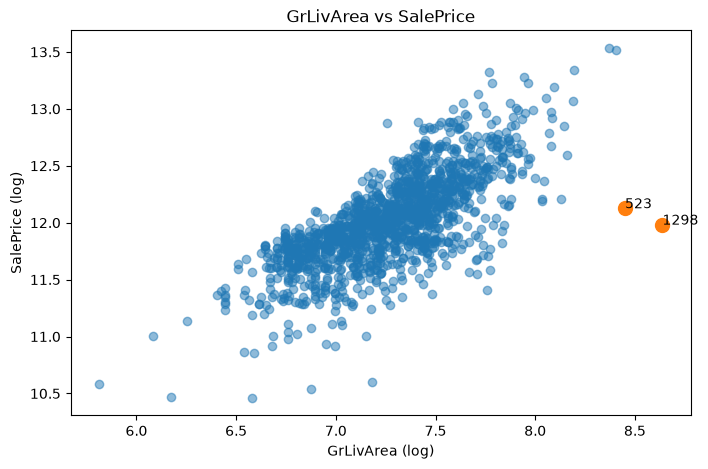

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_hp['GrLivArea'],
    df_hp['SalePrice'],
    alpha=0.5
)

plt.scatter(
    df_hp.loc[[523, 1298], 'GrLivArea'],
    df_hp.loc[[523, 1298], 'SalePrice'],
    s=100
)

for idx in [523, 1298]:
    plt.annotate(
        str(idx),
        (
            df_hp.loc[idx, 'GrLivArea'],
            df_hp.loc[idx, 'SalePrice']
        )
    )

plt.xlabel('GrLivArea (log)')
plt.ylabel('SalePrice (log)')
plt.title('GrLivArea vs SalePrice')

plt.show()

In [ ]:
pd.set_option('display.max_columns', None)
display(
    df_hp.loc[
        [523, 1298]
    ]
)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,HouseAge,RemodAge,GarageAge,TotalSF,TotalBathrooms,TotalPorchSF,HasGarage,HasBasement,HasPool,HasFireplace,IsRemodeled,QualGrLivArea
523,524,60,RL,11.401754,10.598982,Pave,None,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,6.637258,Ex,TA,PConc,Ex,TA,Gd,GLQ,7.723562,Unf,0,878,3138,GasA,Ex,Y,SBrkr,8.051341,1538,0,8.450198,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,2007.0,Fin,3,884,TA,TA,Y,5.342334,6.008813,0,0,0,0,None,None,None,0,10,2007,New,Partial,12.126759,0,0,0.0,7814,4.5,614,1,1,0,1,1,46760
1298,1299,60,RL,17.691806,11.064871,Pave,None,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,6.680855,Ex,TA,PConc,Ex,TA,Gd,GLQ,8.638525,Unf,0,466,6110,GasA,Ex,Y,SBrkr,8.453614,950,0,8.637994,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,5.370638,5.680173,0,0,0,480,Gd,None,None,0,1,2008,New,Partial,11.982929,0,0,0.0,11752,4.5,506,1,1,1,1,0,56420


In [ ]:
comparison = df_hp[
    (df_hp['Neighborhood'] == 'Edwards') &
    (df_hp['OverallQual'] >= 8)
][[
    'GrLivArea',
    'TotalSF',
    'OverallQual',
    'SaleType',
    'SaleCondition',
    'SalePrice'
]].sort_values('GrLivArea')

display(comparison)

,GrLivArea,TotalSF,OverallQual,SaleType,SaleCondition,SalePrice
724,7.437206,3396,9,WD,Normal,12.676076
523,8.450198,7814,10,New,Partial,12.126759
1298,8.637994,11752,10,New,Partial,11.982929


In [ ]:
tracker.resolve_finding(
    finding_id=GrLivArea['id'].iloc[0],
    resolution=(
        'Records 523 and 1298 were retained. '
        'They are multivariate outliers, but no evidence '
        'of data error was found.'
    )
)
tracker.log(
    var='GrLivArea',
    stage='DP - Outliers',
    action='retain_outliers',
    method='multivariate_analysis',
    before='Records 523 and 1298 identified as multivariate outliers',
    after='Retained: extreme but plausible observations'
)

44

In [ ]:
tracker.log(
    var='multiple',
    stage='DP - Outliers',
    action='retain_outliers',
    method='IQR + domain + multivariate_analysis',
    before='Outliers detected across multiple numeric variables',
    after='Retained: no confirmed data errors; extremes considered plausible'
)

45

In [ ]:
tracker.resolve_finding(
    17,
    resolution=(
        'Resolved in DP - Outliers. Upper-tail observations were '
        'reviewed and retained because no confirmed data errors '
        'were identified.'
    )
)

In [ ]:

df_hp.to_parquet(
    'processed/05_outliers.parquet',
    index=False
)
tracker.save()

### DP_Feature_Selection

DATA PREPARATION
- Structure
- Missing Values
- Feature Engineer
- Transformations
- Outliers
- **Feature Selection**
- Scaling

- Low Variance

- Redundancy

- Relationship with Target

- Multicollinearity

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.stats import boxcox, yeojohnson
from data_tracker import DataTracker

In [ ]:
df_hp = pd.read_parquet('processed/05_outliers.parquet')
tracker = DataTracker.load(df_hp)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.0,0.0,0.000000,1.000000,1460.000000,730.500000,730.500000,421.610009,0.000000,-1.200000
1,MSSubClass,str,nominal,15,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,str,nominal,5,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,115,0,0.0,0.0,0.000000,4.582576,17.691806,8.277181,8.366600,1.299647,0.281391,4.993690
4,LotArea,float64,continuous,1073,0,0.0,0.0,0.000000,7.170120,12.279532,9.110838,9.156781,0.517448,-0.137994,4.713358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,HasBasement,int64,NaN,2,0,0.0,37.0,2.534247,0.000000,1.000000,0.974658,1.000000,0.157217,-6.046534,34.607975
89,HasPool,int64,NaN,2,0,0.0,1453.0,99.520548,0.000000,1.000000,0.004795,0.000000,0.069100,14.352680,204.279269
90,HasFireplace,int64,NaN,2,0,0.0,690.0,47.260274,0.000000,1.000000,0.527397,1.000000,0.499420,-0.109867,-1.990658
91,IsRemodeled,int64,NaN,2,0,0.0,764.0,52.328767,0.000000,1.000000,0.476712,0.000000,0.499629,0.093348,-1.994020


In [ ]:
#LOW VARIANCE
#Variables que casi no cambian

low_variance_analysis = []

for var in df_hp.columns:

    if var == 'SalePrice':
        continue

    counts = df_hp[var].value_counts(
        normalize=True,
        dropna=False
    )

    low_variance_analysis.append({
        'var': var,
        'unique_count': df_hp[var].nunique(dropna=False),
        'dominant_value': counts.index[0],
        'dominant_pct': counts.iloc[0] * 100
    })

low_variance_analysis = pd.DataFrame(
    low_variance_analysis
).sort_values(
    'dominant_pct',
    ascending=False
)

display(low_variance_analysis.head(20))

,var,unique_count,dominant_value,dominant_pct
9,Utilities,2,AllPub,99.931507
5,Street,2,Pave,99.589041
88,HasPool,2,0,99.520548
71,PoolArea,8,0,99.520548
72,PoolQC,4,None,99.520548
14,Condition2,8,Norm,98.972603
69,3SsnPorch,20,0,98.356164
45,LowQualFinSF,24,0,98.219178
22,RoofMatl,8,CompShg,98.219178
39,Heating,6,GasA,97.808219


In [ ]:
low_variance_candidates = low_variance_analysis[
    low_variance_analysis['dominant_pct'] >= 95
]

low_variance_candidates['var'].tolist()

['Utilities',
 'Street',
 'HasPool',
 'PoolArea',
 'PoolQC',
 'Condition2',
 '3SsnPorch',
 'LowQualFinSF',
 'RoofMatl',
 'Heating',
 'HasBasement',
 'MiscVal',
 'MiscFeature',
 'KitchenAbvGr']

In [ ]:
low_var_names = low_variance_candidates['var'].tolist()

numeric_low_var = [
    var for var in low_var_names
    if pd.api.types.is_numeric_dtype(df_hp[var])
]

target_corr = (
     df_hp[numeric_low_var + ['SalePrice']]
    .corr()['SalePrice']
    .drop('SalePrice')
    .sort_values(key=abs, ascending=False)
)

display(target_corr)

HasBasement     0.199634
KitchenAbvGr   -0.147548
HasPool         0.069835
PoolArea        0.069798
3SsnPorch       0.054900
LowQualFinSF   -0.037963
MiscVal        -0.020021
Name: SalePrice, dtype: float64

In [ ]:
categorical_low_var = [
    var for var in low_variance_candidates['var']
    if not pd.api.types.is_numeric_dtype(df_hp[var])
]

for var in categorical_low_var:
    display(
        df_hp.groupby(var)['SalePrice']
        .agg(['count', 'mean', 'median'])
        .sort_values('mean', ascending=False)
    )

,count,mean,median
Utilities,,,
AllPub,1459,12.024183,12.001505
NoSeWa,1,11.831379,11.831379


,count,mean,median
Street,,,
Pave,1454,12.025522,12.001505
Grvl,6,11.667435,11.645452


,count,mean,median
PoolQC,,,
Ex,2,12.944240,12.944240
Fa,2,12.267734,12.267734
Gd,3,12.185588,12.049419
None,1453,12.022115,12.000892


,count,mean,median
Condition2,,,
PosA,1,12.691580,12.691580
PosN,2,12.493879,12.493879
RRAe,1,12.154779,12.154779
Norm,1445,12.025895,12.004568
RRAn,1,11.827043,11.827043
Feedr,6,11.670631,11.755864
Artery,2,11.570036,11.570036
RRNn,2,11.435329,11.435329


,count,mean,median
RoofMatl,,,
WdShngl,6,12.763192,12.701772
Membran,1,12.394625,12.394625
WdShake,5,12.384850,12.396693
Metal,1,12.100712,12.100712
Tar&Grv,11,12.068078,12.025749
CompShg,1434,12.019216,11.995352
ClyTile,1,11.982929,11.982929
Roll,1,11.827736,11.827736


,count,mean,median
Heating,,,
GasA,1428,12.032078,12.010666
GasW,18,11.930687,11.812629
OthW,2,11.741606,11.741606
Wall,4,11.429740,11.423422
Floor,1,11.191342,11.191342
Grav,7,11.165886,11.277203


,count,mean,median
MiscFeature,,,
TenC,1,12.429216,12.429216
Gar2,2,12.041560,12.041560
None,1406,12.030112,12.009144
Shed,49,11.868387,11.877569
Othr,2,11.356596,11.356596


In [ ]:
tracker.add_finding(
    var='multiple',
    stage='DP - Feature Selection',
    finding=(
        'Low variance screening identified 14 variables with '
        'dominant_pct >= 95%. These require redundancy and '
        'predictive-value evaluation before keep/drop decisions.'
    )
)
tracker.add_finding(
    var='HasPool, PoolArea, PoolQC',
    stage='DP - Feature Selection',
    finding=(
        'Low-variance pool-related features may contain redundant information.'
    )
)

26

In [ ]:

# Redundancy  
# Variables que representan información muy similar
# o que nosotros mismos duplicamos con Feature Engineering


numeric_cols = df_hp.select_dtypes(
    include='number'
).columns.drop('SalePrice')

corr_matrix = df_hp[numeric_cols].corr().abs()

high_corr_pairs = (
    corr_matrix
    .where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'var_1',
    'var_2',
    'correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['correlation'] >= 0.80
].sort_values(
    'correlation',
    ascending=False
)

display(high_corr_pairs)

,var_1,var_2,correlation
276,YearBuilt,HouseAge,0.999036
1194,GarageYrBlt,HasGarage,0.998601
325,YearRemodAdd,RemodAge,0.997931
1580,PoolArea,HasPool,0.989665
1149,Fireplaces,HasFireplace,0.900457
1919,TotalSF,QualGrLivArea,0.888527
1226,GarageCars,GarageArea,0.882475
767,GrLivArea,QualGrLivArea,0.877174
759,GrLivArea,TotalSF,0.848739
742,GrLivArea,TotRmsAbvGrd,0.825498


In [ ]:
tracker.add_finding(
    var='multiple',
    stage='DP - Feature Selection',
    finding=(
        'High-correlation screening identified redundant feature groups, '
        'including temporal derived features, binary existence indicators '
        'and engineered aggregate features. Final keep/drop decisions '
        'require evaluation with the remaining feature-selection criteria.'
    )
)
tracker.add_finding(
    var='YearBuilt, YearRemodAdd, GarageYrBlt',
    stage='DP - Feature Selection',
    finding=(
        'Near-perfect redundancy detected with HouseAge, RemodAge '
        'and GarageAge respectively (correlation > 0.99).'
    )
)

28

In [ ]:
# Relationship with Target
# Numéricas → correlación / asociación
# Categóricas → asociación con SalePrice

In [ ]:
# Variables numéricas excepto target
numeric_features = [
    var for var in df_hp.select_dtypes(include='number').columns
    if var != 'SalePrice'
]

target_relationship = (
    df_hp[numeric_features + ['SalePrice']]
    .corr()['SalePrice']
    .drop('SalePrice')
    .sort_values(key=abs, ascending=False)
)

display(target_relationship)

OverallQual       0.817184
QualGrLivArea     0.800062
TotalSF           0.773277
GrLivArea         0.730255
GarageCars        0.680625
TotalBathrooms    0.673011
GarageArea        0.650888
TotalBsmtSF       0.612134
1stFlrSF          0.608947
FullBath          0.594771
HouseAge         -0.587290
YearBuilt         0.586570
RemodAge         -0.568149
YearRemodAdd      0.565608
TotRmsAbvGrd      0.534422
HasFireplace      0.510026
Fireplaces        0.489449
OpenPorchSF       0.459948
MasVnrArea        0.413318
LotArea           0.399918
TotalPorchSF      0.398387
GarageAge        -0.396053
LotFrontage       0.367189
GarageYrBlt       0.349014
WoodDeckSF        0.343039
HasGarage         0.322999
2ndFlrSF          0.319300
HalfBath          0.313982
BsmtFullBath      0.236224
BsmtUnfSF         0.221985
BedroomAbvGr      0.209044
BsmtFinSF1        0.208099
HasBasement       0.199634
EnclosedPorch    -0.149050
KitchenAbvGr     -0.147548
ScreenPorch       0.121208
IsRemodeled      -0.073761
H

In [ ]:
#Categoricas

import numpy as np
import pandas as pd

def correlation_ratio(categories, values):
    categories = pd.Series(categories)
    values = pd.Series(values)

    codes, _ = pd.factorize(categories)

    overall_mean = values.mean()

    numerator = 0
    denominator = ((values - overall_mean) ** 2).sum()

    for code in np.unique(codes):
        group = values[codes == code]

        numerator += len(group) * (
            group.mean() - overall_mean
        ) ** 2

    if denominator == 0:
        return 0

    return np.sqrt(numerator / denominator)

In [ ]:
categorical_features = df_hp.select_dtypes(
    include=['object', 'category']
).columns

categorical_target_relationship = pd.DataFrame({
    'var': categorical_features,
    'eta': [
        correlation_ratio(
            df_hp[var],
            df_hp['SalePrice']
        )
        for var in categorical_features
    ]
}).sort_values(
    'eta',
    ascending=False
)

display(categorical_target_relationship)

/tmp/ipykernel_13570/1543488682.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df_hp.select_dtypes(


,var,eta
9,Neighborhood,0.755518
19,ExterQual,0.679060
22,BsmtQual,0.672533
31,KitchenQual,0.669059
35,GarageFinish,0.617279
34,GarageType,0.578480
0,MSSubClass,0.574567
33,FireplaceQu,0.557582
21,Foundation,0.551045
28,HeatingQC,0.483236


In [ ]:

# Multicollinearity
# Variables predictoras demasiado relacionadas entre sí

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Solo predictores numéricos
X_vif = df_hp.select_dtypes(include='number').drop(
    columns=['SalePrice']
).copy()

# Quitamos Id porque no es predictor real
X_vif = X_vif.drop(columns=['Id'], errors='ignore')

# Seguridad
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)
X_vif = X_vif.dropna()

vif_results = pd.DataFrame({
    'var': X_vif.columns,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
}).sort_values(
    'VIF',
    ascending=False
)

display(vif_results)

/tmp/ipykernel_13570/402000132.py:21: UserWarning: The design matrix is poorly conditioned (condition number=1.08e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_vif.values, i)
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:2

,var,VIF
4,YearBuilt,1.000800e+15
39,TotalBathrooms,1.000800e+15
35,HouseAge,1.000800e+15
18,HalfBath,1.000800e+15
17,FullBath,1.000800e+15
16,BsmtHalfBath,1.000800e+15
15,BsmtFullBath,1.000800e+15
34,YrSold,1.000800e+15
41,HasGarage,2.526129e+06
23,GarageYrBlt,2.459834e+06


In [ ]:
tracker.add_finding(
    var='multiple',
    stage='DP - Feature Selection',
    finding=(
        'VIF analysis identified severe multicollinearity, '
        'including perfect linear dependencies (VIF = inf) '
        'and several predictors with VIF > 10.'
    )
)

29

In [ ]:
# Final Selection
#    ├── Keep
#    ├── Drop
#    └── Pending / evaluar con modelo

In [ ]:
display(
    tracker.findings[
        tracker.findings['stage'] == 'DP - Feature Selection'
    ]
)

,id,var,stage,finding,status,resolution
24,25,multiple,DP - Feature Selection,Low variance screening identified 14 variables...,pending,None
25,26,"HasPool, PoolArea, PoolQC",DP - Feature Selection,Low-variance pool-related features may contain...,pending,None
26,27,multiple,DP - Feature Selection,High-correlation screening identified redundan...,pending,None
27,28,"YearBuilt, YearRemodAdd, GarageYrBlt",DP - Feature Selection,Near-perfect redundancy detected with HouseAge...,pending,None
28,29,multiple,DP - Feature Selection,VIF analysis identified severe multicollineari...,pending,None


In [ ]:
multiple=tracker.findings[
    (tracker.findings['var']=='multiple') &
    (tracker.findings['stage']=='DP - Feature Selection' )                       
].iloc[0]
display(multiple)

id                                                           25
var                                                    multiple
stage                                    DP - Feature Selection
finding       Low variance screening identified 14 variables...
status                                                  pending
resolution                                                 None
Name: 24, dtype: object

In [ ]:
drop_low_variance = [
    'Utilities',
    'Street',
    '3SsnPorch',
    'LowQualFinSF',
    'MiscVal'
]

keep_low_variance = [
    'Heating',
    'HasBasement',
    'KitchenAbvGr'
]

review_low_variance = [
    'Condition2',
    'RoofMatl',
    'MiscFeature'
]

deferred_low_variance = [
    'HasPool',
    'PoolArea',
    'PoolQC'
]

In [ ]:
for var in drop_low_variance:
    tracker.add_plan(
        var=var,
        stage='DP - Feature Selection',
        action='drop',
        method='low_variance',
        params={
            'reason': 'near_constant_and_low_target_relationship'
        }
    )
tracker.resolve_finding(
    25,
    resolution=(
        'Low-variance features evaluated using dominant percentage and '
        'target relationship. Utilities, Street, 3SsnPorch, '
        'LowQualFinSF and MiscVal selected for removal. '
        'HasPool, PoolArea and PoolQC deferred to redundancy analysis. '
        'Remaining features retained.'
    )
)

In [ ]:
display(
    tracker.findings[
        tracker.findings['stage'] == 'DP - Feature Selection'
    ]
)

,id,var,stage,finding,status,resolution
24,25,multiple,DP - Feature Selection,Low variance screening identified 14 variables...,resolved,Low-variance features evaluated using dominant...
25,26,"HasPool, PoolArea, PoolQC",DP - Feature Selection,Low-variance pool-related features may contain...,pending,None
26,27,multiple,DP - Feature Selection,High-correlation screening identified redundan...,pending,None
27,28,"YearBuilt, YearRemodAdd, GarageYrBlt",DP - Feature Selection,Near-perfect redundancy detected with HouseAge...,pending,None
28,29,multiple,DP - Feature Selection,VIF analysis identified severe multicollineari...,pending,None


In [ ]:
for var in ['HasPool', 'PoolQC']:
    tracker.add_plan(
        var=var,
        stage='DP - Feature Selection',
        action='drop',
        method='redundancy',
        params={
            'reason': 'redundant_pool_feature',
            'retained_feature': 'PoolArea'
        }
    )

In [ ]:
tracker.resolve_finding(
    26,
    resolution=(
        'PoolArea retained as the primary pool representation. '
        'HasPool and PoolQC planned for removal due to redundancy '
        'and extremely low occurrence.'
    )
)

In [ ]:
display(
    tracker.findings[
        tracker.findings['stage'] == 'DP - Feature Selection'
    ]
)

,id,var,stage,finding,status,resolution
24,25,multiple,DP - Feature Selection,Low variance screening identified 14 variables...,resolved,Low-variance features evaluated using dominant...
25,26,"HasPool, PoolArea, PoolQC",DP - Feature Selection,Low-variance pool-related features may contain...,resolved,PoolArea retained as the primary pool represen...
26,27,multiple,DP - Feature Selection,High-correlation screening identified redundan...,pending,None
27,28,"YearBuilt, YearRemodAdd, GarageYrBlt",DP - Feature Selection,Near-perfect redundancy detected with HouseAge...,pending,None
28,29,multiple,DP - Feature Selection,VIF analysis identified severe multicollineari...,pending,None


In [ ]:
tracker.resolve_finding(
    27,
    resolution=(
        'High-correlation pairs were reviewed. Pool-related redundancy '
        'was addressed separately, and temporal redundancy is evaluated '
        'in its dedicated finding. Remaining correlated features were '
        'retained at this stage because high correlation alone does not '
        'establish informational equivalence; multicollinearity will be '
        'considered in the VIF analysis.'
    )
)

In [ ]:
display(
    tracker.findings[
        tracker.findings['stage'] == 'DP - Feature Selection'
    ]
)

,id,var,stage,finding,status,resolution
24,25,multiple,DP - Feature Selection,Low variance screening identified 14 variables...,resolved,Low-variance features evaluated using dominant...
25,26,"HasPool, PoolArea, PoolQC",DP - Feature Selection,Low-variance pool-related features may contain...,resolved,PoolArea retained as the primary pool represen...
26,27,multiple,DP - Feature Selection,High-correlation screening identified redundan...,resolved,High-correlation pairs were reviewed. Pool-rel...
27,28,"YearBuilt, YearRemodAdd, GarageYrBlt",DP - Feature Selection,Near-perfect redundancy detected with HouseAge...,pending,None
28,29,multiple,DP - Feature Selection,VIF analysis identified severe multicollineari...,pending,None


In [ ]:
for var in [
    'YearBuilt',
    'YearRemodAdd',
    'GarageYrBlt'
]:
    tracker.add_plan(
        var=var,
        stage='DP - Feature Selection',
        action='drop',
        method='redundancy',
        params={
            'reason': 'replaced_by_derived_age_feature'
        }
    )

In [ ]:
tracker.resolve_finding(
    28,
    resolution=(
        'Original year features selected for removal due to near-perfect '
        'redundancy with derived age features. HouseAge, RemodAge and '
        'GarageAge retained as the model representations.'
    )
)

In [ ]:
display(
    tracker.findings[
        tracker.findings['stage'] == 'DP - Feature Selection'
    ]
)

,id,var,stage,finding,status,resolution
24,25,multiple,DP - Feature Selection,Low variance screening identified 14 variables...,resolved,Low-variance features evaluated using dominant...
25,26,"HasPool, PoolArea, PoolQC",DP - Feature Selection,Low-variance pool-related features may contain...,resolved,PoolArea retained as the primary pool represen...
26,27,multiple,DP - Feature Selection,High-correlation screening identified redundan...,resolved,High-correlation pairs were reviewed. Pool-rel...
27,28,"YearBuilt, YearRemodAdd, GarageYrBlt",DP - Feature Selection,Near-perfect redundancy detected with HouseAge...,resolved,Original year features selected for removal du...
28,29,multiple,DP - Feature Selection,VIF analysis identified severe multicollineari...,pending,None


In [ ]:
planned_drops = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Feature Selection') &
    (tracker.plans['action'] == 'drop') &
    (tracker.plans['status'] == 'planned'),
    'var'
].tolist()

planned_drops

['Utilities',
 'Street',
 '3SsnPorch',
 'LowQualFinSF',
 'MiscVal',
 'HasPool',
 'PoolQC',
 'YearBuilt',
 'YearRemodAdd',
 'GarageYrBlt']

In [ ]:
df_vif_review = df_hp.drop(
    columns=planned_drops,
    errors='ignore'
)

X_vif_review = df_vif_review.select_dtypes(
    include='number'
).drop(
    columns=['SalePrice', 'Id'],
    errors='ignore'
).copy()

X_vif_review = X_vif_review.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

vif_review = pd.DataFrame({
    'var': X_vif_review.columns,
    'VIF': [
        variance_inflation_factor(
            X_vif_review.values,
            i
        )
        for i in range(X_vif_review.shape[1])
    ]
}).sort_values(
    'VIF',
    ascending=False
)

display(vif_review)

/tmp/ipykernel_13570/1603976906.py:21: UserWarning: The design matrix is poorly conditioned (condition number=8.32e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/opt/conda/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMat

,var,VIF
12,BsmtFullBath,1.000800e+15
13,BsmtHalfBath,1.000800e+15
14,FullBath,1.000800e+15
33,TotalBathrooms,1.000800e+15
15,HalfBath,1.000800e+15
32,TotalSF,4.284359e+02
8,TotalBsmtSF,1.343863e+02
39,QualGrLivArea,9.583025e+01
11,GrLivArea,5.075441e+01
10,2ndFlrSF,3.139466e+01


In [ ]:
for var in [
    'FullBath',
    'HalfBath',
    'BsmtFullBath',
    'BsmtHalfBath',
    'HasGarage'
]:
    tracker.add_plan(
        var=var,
        stage='DP - Feature Selection',
        action='drop',
        method='multicollinearity',
        params={
            'reason': 'redundant_with_engineered_feature'
        }
    )

In [ ]:
planned_drops = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Feature Selection') &
    (tracker.plans['action'] == 'drop') &
    (tracker.plans['status'] == 'planned'),
    'var'
].tolist()

print(len(planned_drops))
print(planned_drops)

15
['Utilities', 'Street', '3SsnPorch', 'LowQualFinSF', 'MiscVal', 'HasPool', 'PoolQC', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'HasGarage']


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif_review = (
    df_hp
    .drop(columns=planned_drops, errors='ignore')
    .select_dtypes(include='number')
    .drop(columns=['SalePrice', 'Id'], errors='ignore')
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# IMPORTANTE: agregar intercepto
X_vif_const = add_constant(X_vif_review)

vif_review = pd.DataFrame({
    'var': X_vif_const.columns,
    'VIF': [
        variance_inflation_factor(X_vif_const.values, i)
        for i in range(X_vif_const.shape[1])
    ]
})

# La constante no es una feature
vif_review = (
    vif_review[
        vif_review['var'] != 'const'
    ]
    .sort_values('VIF', ascending=False)
    .reset_index(drop=True)
)

display(vif_review)

,var,VIF
0,TotalSF,421.864004
1,TotalBsmtSF,131.767315
2,QualGrLivArea,94.322619
3,GrLivArea,48.848902
4,2ndFlrSF,31.228577
5,1stFlrSF,20.292092
6,OverallQual,19.693602
7,Fireplaces,6.258950
8,HasFireplace,6.136840
9,GarageCars,5.735496


In [ ]:
for var in [
    'TotalBsmtSF',
    'GrLivArea',
    '1stFlrSF',
    '2ndFlrSF'
]:
    tracker.add_plan(
        var=var,
        stage='DP - Feature Selection',
        action='drop',
        method='multicollinearity',
        params={
            'reason': 'redundant_with_engineered_aggregate_features'
        }
    )

In [ ]:
planned_drops = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Feature Selection') &
    (tracker.plans['action'] == 'drop') &
    (tracker.plans['status'] == 'planned'),
    'var'
].tolist()

print(len(planned_drops))
print(planned_drops)

19
['Utilities', 'Street', '3SsnPorch', 'LowQualFinSF', 'MiscVal', 'HasPool', 'PoolQC', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'HasGarage', 'TotalBsmtSF', 'GrLivArea', '1stFlrSF', '2ndFlrSF']


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif_review = (
    df_hp
    .drop(columns=planned_drops, errors='ignore')
    .select_dtypes(include='number')
    .drop(columns=['SalePrice', 'Id'], errors='ignore')
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# IMPORTANTE: agregar intercepto
X_vif_const = add_constant(X_vif_review)

vif_review = pd.DataFrame({
    'var': X_vif_const.columns,
    'VIF': [
        variance_inflation_factor(X_vif_const.values, i)
        for i in range(X_vif_const.shape[1])
    ]
})

# La constante no es una feature
vif_review = (
    vif_review[
        vif_review['var'] != 'const'
    ]
    .sort_values('VIF', ascending=False)
    .reset_index(drop=True)
)

display(vif_review)

,var,VIF
0,QualGrLivArea,17.950540
1,TotalSF,14.760712
2,OverallQual,6.324960
3,Fireplaces,6.219174
4,HasFireplace,5.976172
5,GarageCars,5.675544
6,HouseAge,5.292092
7,GarageArea,5.289104
8,BsmtUnfSF,5.051793
9,TotRmsAbvGrd,4.495774


In [ ]:
tracker.resolve_finding(
    29,
    resolution=(
        'Severe multicollinearity was reduced by removing redundant '
        'original and engineered predictors. TotalSF and QualGrLivArea '
        'were retained despite elevated VIF because they provide compact '
        'engineered representations with strong target relationships. '
        'Remaining multicollinearity was considered acceptable for '
        'subsequent model evaluation.'
    )
)

In [ ]:
#Ejecutamos el plan y eliminamos los 19 vars

planned_drops = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Feature Selection') &
    (tracker.plans['action'] == 'drop') &
    (tracker.plans['status'] == 'planned'),
    'var'
].tolist()

print(f'Features a eliminar: {len(planned_drops)}')
print(planned_drops)

Features a eliminar: 19
['Utilities', 'Street', '3SsnPorch', 'LowQualFinSF', 'MiscVal', 'HasPool', 'PoolQC', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'HasGarage', 'TotalBsmtSF', 'GrLivArea', '1stFlrSF', '2ndFlrSF']


In [ ]:
df_fs = df_hp.drop(
    columns=planned_drops,
    errors='raise'
).copy()

In [ ]:
print('Antes:', df_hp.shape)
print('Después:', df_fs.shape)
print('Eliminadas:', df_hp.shape[1] - df_fs.shape[1])

Antes: (1460, 93)
Después: (1460, 74)
Eliminadas: 19


In [ ]:
remaining_drops = [
    var for var in planned_drops
    if var in df_fs.columns
]

print('Variables planeadas que siguen presentes:', remaining_drops)

Variables planeadas que siguen presentes: []


In [ ]:
mask = (
    (tracker.plans['stage'] == 'DP - Feature Selection') &
    (tracker.plans['action'] == 'drop') &
    (tracker.plans['status'] == 'planned')
)

tracker.plans.loc[mask, 'status'] = 'applied'

for var in planned_drops:
    tracker.log(
        var=var,
        stage='DP - Feature Selection',
        action='drop',
        method='feature_selection',
        before='feature present',
        after='feature removed'
    )

In [ ]:
# Ver qué variables de esos findings todavía existen
vars_check = [
    'GarageYrBlt',
    'Utilities',
    'Street',
    'Condition2',
    'RoofMatl',
    'Heating',
    'GarageCond',
    'GarageQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'YearBuilt',
    'TotRmsAbvGrd',
    'TotalBsmtSF',
    '1stFlrSF'
]

for var in vars_check:
    print(f'{var:15} -> {"PRESENT" if var in df_hp.columns else "DROPPED"}')

GarageYrBlt     -> PRESENT
Utilities       -> PRESENT
Street          -> PRESENT
Condition2      -> PRESENT
RoofMatl        -> PRESENT
Heating         -> PRESENT
GarageCond      -> PRESENT
GarageQual      -> PRESENT
GrLivArea       -> PRESENT
GarageCars      -> PRESENT
GarageArea      -> PRESENT
YearBuilt       -> PRESENT
TotRmsAbvGrd    -> PRESENT
TotalBsmtSF     -> PRESENT
1stFlrSF        -> PRESENT


In [ ]:
tracker.resolve_finding(
    8,
    resolution='Resolved during Data Preparation; GarageYrBlt was removed during feature selection.'
)

tracker.resolve_finding(
    9,
    resolution='Resolved during feature selection; Utilities was removed due to near-constant behavior and negligible predictive value.'
)

tracker.resolve_finding(
    10,
    resolution='Resolved during feature selection; Street was removed due to near-constant behavior and very weak predictive value.'
)

tracker.resolve_finding(
    18,
    resolution='Resolved during Data Preparation; GrLivArea was removed during feature selection in favor of engineered/redundancy considerations.'
)

tracker.resolve_finding(
    20,
    resolution='Resolved during feature selection; YearBuilt and GarageYrBlt were removed after temporal engineered features were introduced.'
)

tracker.resolve_finding(
    21,
    resolution='Resolved during feature selection; GrLivArea was removed, resolving the identified redundancy with TotRmsAbvGrd.'
)

tracker.resolve_finding(
    22,
    resolution='Resolved during feature selection; TotalBsmtSF and 1stFlrSF were removed after redundancy analysis.'
)

In [ ]:
for finding_id, var in [
    (11, 'Condition2'),
    (12, 'RoofMatl'),
    (13, 'Heating'),
    (14, 'GarageCond'),
    (15, 'GarageQual')
]:
    tracker.resolve_finding(
        finding_id,
        resolution=(
            f'{var} was reviewed during feature selection and retained; '
            'near-constant behavior alone was not considered sufficient '
            'evidence for removal.'
        )
    )

In [ ]:
tracker.resolve_finding(
    19,
    resolution=(
        'Reviewed during feature selection and VIF analysis. '
        'GarageCars and GarageArea were retained in the final feature set.'
    )
)

In [ ]:


df_fs.to_parquet(
    'processed/06_feature_selection.parquet',
    index=False
)
tracker.save()

### DP_Scaling

DATA PREPARATION
- Structure
- Missing Values
- Feature Engineer
- Transformations
- Outliers
- Feature Selection
- **Scaling**

- Identificar variables candidatas

- Decidir cuáles necesitan scaling

- Elegir método StandardScaler,RobustScaler,MinMaxScaler

- Registrar PLAN

In [ ]:
import pandas as pd

In [ ]:
df_hp = pd.read_parquet('processed/06_feature_selection.parquet')
tracker = DataTracker.load(df_hp)
profile = tracker.profile
display(profile)

,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1460,0,0.0,0.0,0.000000,1.000000,1460.000000,730.500000,730.500000,421.610009,0.000000,-1.200000
1,MSSubClass,str,nominal,15,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,str,nominal,5,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,115,0,0.0,0.0,0.000000,4.582576,17.691806,8.277181,8.366600,1.299647,0.281391,4.993690
4,LotArea,float64,continuous,1073,0,0.0,0.0,0.000000,7.170120,12.279532,9.110838,9.156781,0.517448,-0.137994,4.713358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,TotalPorchSF,int64,NaN,427,0,0.0,254.0,17.397260,0.000000,1027.000000,181.329452,164.000000,156.656097,1.102313,1.764561
70,HasBasement,int64,NaN,2,0,0.0,37.0,2.534247,0.000000,1.000000,0.974658,1.000000,0.157217,-6.046534,34.607975
71,HasFireplace,int64,NaN,2,0,0.0,690.0,47.260274,0.000000,1.000000,0.527397,1.000000,0.499420,-0.109867,-1.990658
72,IsRemodeled,int64,NaN,2,0,0.0,764.0,52.328767,0.000000,1.000000,0.476712,0.000000,0.499629,0.093348,-1.994020


In [ ]:
scaling_analysis = profile.loc[
    profile['data_type'].isin(['int64', 'float64']),
    [
        'var',
        'variable_type',
        'unique_count',
        'min',
        'max'
    ]
]

display(scaling_analysis)

,var,variable_type,unique_count,min,max
0,Id,identifier,1460,1.000000,1460.000000
3,LotFrontage,continuous,115,4.582576,17.691806
4,LotArea,continuous,1073,7.170120,12.279532
15,OverallQual,ordinal,10,1.000000,10.000000
16,OverallCond,ordinal,9,1.000000,9.000000
22,MasVnrArea,continuous,327,0.000000,7.378384
30,BsmtFinSF1,continuous,637,0.000000,8.638525
32,BsmtFinSF2,continuous,144,0.000000,1474.000000
33,BsmtUnfSF,continuous,780,0.000000,2336.000000
38,BedroomAbvGr,discrete,8,0.000000,8.000000


In [ ]:
tracker.set_variable_types(
    [
        'HouseAge',
        'RemodAge',
        'GarageAge',
        'TotalSF',
        'TotalPorchSF',
        'QualGrLivArea'
    ],
    'continuous'
)

tracker.set_variable_types(
    [
        'TotalBathrooms'
    ],
    'discrete'
)

tracker.set_variable_types(
    [
        'HasBasement',
        'HasFireplace',
        'IsRemodeled'
    ],
    'binary'
)

In [ ]:
scaling_candidates = profile.loc[
    (profile['variable_type'] == 'continuous') &
    (profile['var'] != 'SalePrice'),
    'var'
].tolist()

scaling_candidates

['LotFrontage',
 'LotArea',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 'ScreenPorch',
 'PoolArea',
 'HouseAge',
 'RemodAge',
 'GarageAge',
 'TotalSF',
 'TotalPorchSF',
 'QualGrLivArea']

In [ ]:
for var in scaling_candidates:
    tracker.add_plan(
        var=var,
        stage='DP - Scaling',
        action='scale',
        method='model_dependent',
        params={}
    )

In [ ]:
df_fs.to_parquet(
    'processed/07_scaling.parquet',
    index=False
)
tracker.save()

### Final Validation DP

In [ ]:
import pandas as pd

In [ ]:
df_hp = pd.read_parquet('processed/07_scaling.parquet')
tracker = DataTracker.load(df_hp)
profile = tracker.profile

In [ ]:
print('=== DP FINAL VALIDATION ===')

# 1. Estructura
print('\n[STRUCTURE]')
print('Shape:', df_hp.shape)
print('Duplicated rows:', df_hp.duplicated().sum())

# 2. Missing / infinitos
print('\n[MISSING / INFINITE]')
print('Missing:', df_hp.isna().sum().sum())

numeric_df = df_hp.select_dtypes(include='number')
print('Infinite:', np.isinf(numeric_df).sum().sum())

# 3. Target
print('\n[TARGET]')
print('SalePrice exists:', 'SalePrice' in df_hp.columns)
print('SalePrice missing:', df_hp['SalePrice'].isna().sum())
print('SalePrice infinite:', np.isinf(df_hp['SalePrice']).sum())

# 4. Binarias
binary_cols = [
    'HasBasement',
    'HasFireplace',
    'IsRemodeled'
]

print('\n[BINARY FEATURES]')
for col in binary_cols:
    if col in df_hp.columns:
        print(col, sorted(df_hp[col].dropna().unique()))

# 5. Engineered temporal features
print('\n[TEMPORAL FEATURES]')
for col in ['HouseAge', 'RemodAge', 'GarageAge']:
    if col in df_hp.columns:
        print(
            col,
            'min =', df_hp[col].min(),
            'max =', df_hp[col].max()
        )

# 6. Tracker
print('\n[TRACKER]')
print(
    'Pending findings:',
    (tracker.findings['status'] == 'pending').sum()
)

print(
    'Planned actions:',
    (tracker.plans['status'] == 'planned').sum()
)

=== DP FINAL VALIDATION ===

[STRUCTURE]
Shape: (1460, 74)
Duplicated rows: 0

[MISSING / INFINITE]
Missing: 0
Infinite: 0

[TARGET]
SalePrice exists: True
SalePrice missing: 0
SalePrice infinite: 0

[BINARY FEATURES]
HasBasement [np.int64(0), np.int64(1)]
HasFireplace [np.int64(0), np.int64(1)]
IsRemodeled [np.int64(0), np.int64(1)]

[TEMPORAL FEATURES]
HouseAge min = 0 max = 136
RemodAge min = 0 max = 60
GarageAge min = 0.0 max = 107.0

[TRACKER]
Pending findings: 0
Planned actions: 62


In [ ]:
display(
    tracker.findings[
        tracker.findings['status'] == 'pending'
    ]
)

,id,var,stage,finding,status,resolution


In [ ]:
planned = tracker.plans[
    tracker.plans['status'] == 'planned'
]

display(
    planned.groupby(
        ['stage', 'action', 'method']
    )
    .size()
    .reset_index(name='count')
)

,stage,action,method,count
0,DP - Encoding,encode,onehot,25
1,DP - Encoding,encode,ordinal,19
2,DP - Scaling,scale,model_dependent,18


In [ ]:
df_hp.to_parquet(
    'processed/08_dp_final.parquet',
    index=False
)

tracker.save()

## 4. Modelado y Entrenamiento

 **Data Split**
   - Define predictors (`X`) and target (`y`)
   - Split data into Train and Test sets

**Preprocessing Pipeline**
   - Ordinal Encoding
   - One-Hot Encoding
   - Scaling according to model requirements

**Baseline Model**
   - Establish an initial performance benchmark

**Candidate Models**
   - Define the models to be evaluated

**Training**
   - Train candidate models using the training data

**Validation and Comparison**
   - Evaluate and compare model performance
   - Use cross-validation when appropriate

**Final Evaluation**
   - Evaluate the selected model on the untouched Test set
   - Report final performance metrics

In [646]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from mlflow.models import infer_signature
from sklearn.model_selection import cross_validate
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri(
    "http://mlflow:5000"
)

mlflow.set_experiment(
    "house-prices-modeling"
)


<Experiment: artifact_location='mlflow-artifacts:/6', creation_time=1791143086121, effective_trace_archival_retention=None, experiment_id='6', last_update_time=1791143086121, lifecycle_stage='active', name='house-prices-modeling', tags={}, trace_location=None, workspace='default'>

### Data Split

In [647]:
# Predictors and target
X = df_hp.drop(columns=['SalePrice'])
y = df_hp['SalePrice']

# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print('X_train:', X_train.shape)
print('X_test: ', X_test.shape)
print('y_train:', y_train.shape)
print('y_test: ', y_test.shape)

X_train: (1168, 73)
X_test:  (292, 73)
y_train: (1168,)
y_test:  (292,)


### Preprocessing Pipeline

In [648]:
# 2. Preprocessing Pipeline  obtenemos los vars que ya tenemos en plans y recuperamos solo los que pasaron feature selection

ordinal_cols = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Encoding') &
    (tracker.plans['method'] == 'ordinal') &
    (tracker.plans['var'].isin(X_train.columns)),
    'var'
].tolist()

onehot_cols = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Encoding') &
    (tracker.plans['method'] == 'onehot') &
    (tracker.plans['var'].isin(X_train.columns)),
    'var'
].tolist()

scaling_cols = tracker.plans.loc[
    (tracker.plans['stage'] == 'DP - Scaling') &
    (tracker.plans['method'] == 'model_dependent') &
    (tracker.plans['var'].isin(X_train.columns)),
    'var'
].tolist()

print('Ordinal:', len(ordinal_cols))
print('One-Hot:', len(onehot_cols))
print('Scaling:', len(scaling_cols))

Ordinal: 17
One-Hot: 24
Scaling: 18


In [649]:
#Ordinals

ordinal_categories = []

for col in ordinal_cols:

    params = tracker.plans.loc[
        (tracker.plans['var'] == col) &
        (tracker.plans['stage'] == 'DP - Encoding') &
        (tracker.plans['method'] == 'ordinal'),
        'params'
    ].iloc[0]

    ordinal_categories.append(
        params['categories']
    )

for col, categories in zip(
    ordinal_cols,
    ordinal_categories
):
    print(col, '->', categories)

LotShape -> ['IR3', 'IR2', 'IR1', 'Reg']
LandSlope -> ['Sev', 'Mod', 'Gtl']
ExterQual -> ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ExterCond -> ['Po', 'Fa', 'TA', 'Gd', 'Ex']
BsmtQual -> ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
BsmtCond -> ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
BsmtExposure -> ['None', 'No', 'Mn', 'Av', 'Gd']
BsmtFinType1 -> ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
BsmtFinType2 -> ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
HeatingQC -> ['Po', 'Fa', 'TA', 'Gd', 'Ex']
KitchenQual -> ['Po', 'Fa', 'TA', 'Gd', 'Ex']
Functional -> ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ']
FireplaceQu -> ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
GarageFinish -> ['None', 'Unf', 'RFn', 'Fin']
GarageQual -> ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
GarageCond -> ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
PavedDrive -> ['N', 'P', 'Y']


In [650]:
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()
unencoded_cols = [
    col for col in categorical_cols
    if col not in ordinal_cols
    and col not in onehot_cols
]

print('Categorical features without encoding:')
print(unencoded_cols)

Categorical features without encoding:
[]


/tmp/ipykernel_13570/4262070233.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [651]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

ordinal_encoder = OrdinalEncoder(
    categories=ordinal_categories,
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

onehot_encoder = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal', ordinal_encoder, ordinal_cols),
        ('onehot', onehot_encoder, onehot_cols)
    ],
    remainder='passthrough'
)

### Baseline Model and Training

In [652]:
# 3. Baseline Model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [653]:
with mlflow.start_run(run_name="baseline_linear_regression"):

    mlflow.log_params({
        "model": "LinearRegression",
        "test_size": 0.20,
        "random_state": 42,
        "cv_folds": 5,
        "ordinal_features": len(ordinal_cols),
        "onehot_features": len(onehot_cols),
        "scaling": False
    })

    cv_results = cross_validate(
        baseline_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        }
    )

    baseline_rmse = -cv_results["test_rmse"].mean()
    baseline_mae = -cv_results["test_mae"].mean()
    baseline_r2 = cv_results["test_r2"].mean()

    mlflow.log_metrics({
        "cv_rmse": baseline_rmse,
        "cv_mae": baseline_mae,
        "cv_r2": baseline_r2
    })

    print(f"CV RMSE: {baseline_rmse:.4f}")
    print(f"CV MAE:  {baseline_mae:.4f}")
    print(f"CV R²:   {baseline_r2:.4f}")


    baseline_pipeline.fit(
        X_train,
        y_train
    )


    input_example = X_train.head(5)

    predictions = baseline_pipeline.predict(
        input_example
    )

    signature = infer_signature(
        input_example,
        predictions
    )


    mlflow.sklearn.log_model(
        sk_model=baseline_pipeline,
        name="model",
        signature=signature,
        input_example=input_example
    )

CV RMSE: 0.1589
CV MAE:  0.0908
CV R²:   0.8310


/opt/conda/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run baseline_linear_regression at: http://mlflow:5000/#/experiments/6/runs/880dcce2e2b745dbb5792c88d3382d8e
🧪 View experiment at: http://mlflow:5000/#/experiments/6


### Candidate Models and Evaluation

- Gradient Boosting Regressor

- Ridge Regression

- Random Forest Regressor





In [654]:
#Gradient Boosting Regressor

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline




gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        random_state=42
    ))
])

In [655]:
with mlflow.start_run(run_name="gradient_boosting"):

    mlflow.log_params({
        "model": "GradientBoostingRegressor",
        "test_size": 0.20,
        "random_state": 42,
        "cv_folds": 5,
        "ordinal_features": len(ordinal_cols),
        "onehot_features": len(onehot_cols),
        "scaling": False,

        # Gradient Boosting parameters
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3
    })


    # 2. Cross-validation

    cv_results = cross_validate(
        gb_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        }
    )

    gb_rmse = -cv_results["test_rmse"].mean()
    gb_mae = -cv_results["test_mae"].mean()
    gb_r2 = cv_results["test_r2"].mean()


    # 3. Metrics

    mlflow.log_metrics({
        "cv_rmse": gb_rmse,
        "cv_mae": gb_mae,
        "cv_r2": gb_r2
    })

    print(f"CV RMSE: {gb_rmse:.4f}")
    print(f"CV MAE:  {gb_mae:.4f}")
    print(f"CV R²:   {gb_r2:.4f}")

    # 4. Fit model


    gb_pipeline.fit(
        X_train,
        y_train
    )

    # 5. Model

    input_example = X_train.head(5)

    predictions = gb_pipeline.predict(
        input_example
    )

    signature = infer_signature(
        input_example,
        predictions
    )

    # 6. Log complete pipeline

    mlflow.sklearn.log_model(
        sk_model=gb_pipeline,
        name="model",
        signature=signature,
        input_example=input_example,
        skops_trusted_types=[
        "sklearn.tree._tree.Tree"
    ]
    )

CV RMSE: 0.1271
CV MAE:  0.0874
CV R²:   0.8932


/opt/conda/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run gradient_boosting at: http://mlflow:5000/#/experiments/6/runs/3dcdd892cad64eebaa2e42bbbd156d15
🧪 View experiment at: http://mlflow:5000/#/experiments/6


In [656]:
gb_tuned_pipeline = Pipeline([
    ('preprocessor', preprocessor),

    ('model', GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

In [657]:
with mlflow.start_run(run_name="gradient_boosting_tuned"):


    model_params = gb_tuned_pipeline.named_steps["model"].get_params()

    mlflow.log_params({
        "model": "GradientBoostingRegressor",
        "test_size": 0.20,
        "cv_folds": 5,
        "ordinal_features": len(ordinal_cols),
        "onehot_features": len(onehot_cols),
        "scaling": False,

        "n_estimators": model_params["n_estimators"],
        "learning_rate": model_params["learning_rate"],
        "max_depth": model_params["max_depth"],
        "subsample": model_params["subsample"],
        "loss": model_params["loss"],
        "random_state": model_params["random_state"]
    })


    cv_results = cross_validate(
        gb_tuned_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        }
    )

    tuned_rmse = -cv_results["test_rmse"].mean()
    tuned_mae = -cv_results["test_mae"].mean()
    tuned_r2 = cv_results["test_r2"].mean()


    mlflow.log_metrics({
        "cv_rmse": tuned_rmse,
        "cv_mae": tuned_mae,
        "cv_r2": tuned_r2
    })

    print(f"CV RMSE: {tuned_rmse:.4f}")
    print(f"CV MAE:  {tuned_mae:.4f}")
    print(f"CV R²:   {tuned_r2:.4f}")

    gb_tuned_pipeline.fit(
        X_train,
        y_train
    )

    input_example = X_train.head(5)

    predictions = gb_tuned_pipeline.predict(
        input_example
    )

    signature = infer_signature(
        input_example,
        predictions
    )


    mlflow.sklearn.log_model(
        sk_model=gb_tuned_pipeline,
        name="model",
        signature=signature,
        input_example=input_example,
        skops_trusted_types=[
            "sklearn.tree._tree.Tree"
        ]
    )

CV RMSE: 0.1285
CV MAE:  0.0862
CV R²:   0.8908


/opt/conda/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run gradient_boosting_tuned at: http://mlflow:5000/#/experiments/6/runs/73f3a0f4c9bd4fd3ba719b0bb374ba99
🧪 View experiment at: http://mlflow:5000/#/experiments/6


In [658]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Predicción final sobre Test
y_test_pred = baseline_pipeline.predict(X_test)

test_rmse = mean_squared_error(
    y_test,
    y_test_pred
) ** 0.5

test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

test_r2 = r2_score(
    y_test,
    y_test_pred
)

print(f'Test RMSE: {test_rmse:.4f}')
print(f'Test MAE:  {test_mae:.4f}')
print(f'Test R²:   {test_r2:.4f}')

Test RMSE: 0.1274
Test MAE:  0.0863
Test R²:   0.9130


## 5. Evaluación del modelo

El modelo base de Regresión Lineal fue evaluado inicialmente mediante
validación cruzada de 5 particiones sobre el conjunto de entrenamiento.
Posteriormente, una vez ajustado el pipeline utilizando todo el conjunto
de entrenamiento, se realizó la evaluación final sobre el conjunto de
prueba, que se había mantenido separado durante el desarrollo.

Los resultados obtenidos en Test fueron:

- **RMSE:** 0.1274
- **MAE:** 0.0863
- **R²:** 0.9130

El valor de R² indica que el modelo explica aproximadamente el 91.3 % de
la variabilidad observada en la variable objetivo transformada dentro del
conjunto de prueba.

El RMSE y MAE se encuentran expresados en escala logarítmica debido a la
transformación `log1p` aplicada previamente sobre `SalePrice`. Por esta
razón, estos valores no representan directamente errores monetarios.

Los resultados de Test fueron incluso mejores que los obtenidos en promedio
mediante cross-validation (RMSE = 0.1589, MAE = 0.0908 y R² = 0.8310).
Esta diferencia puede deberse a las características particulares de la
partición de prueba. Por ello, la validación cruzada proporciona una visión
más robusta del comportamiento esperado del modelo que depender únicamente
de una sola partición Train-Test.

## 6. Registra el experimento en MLFlow:

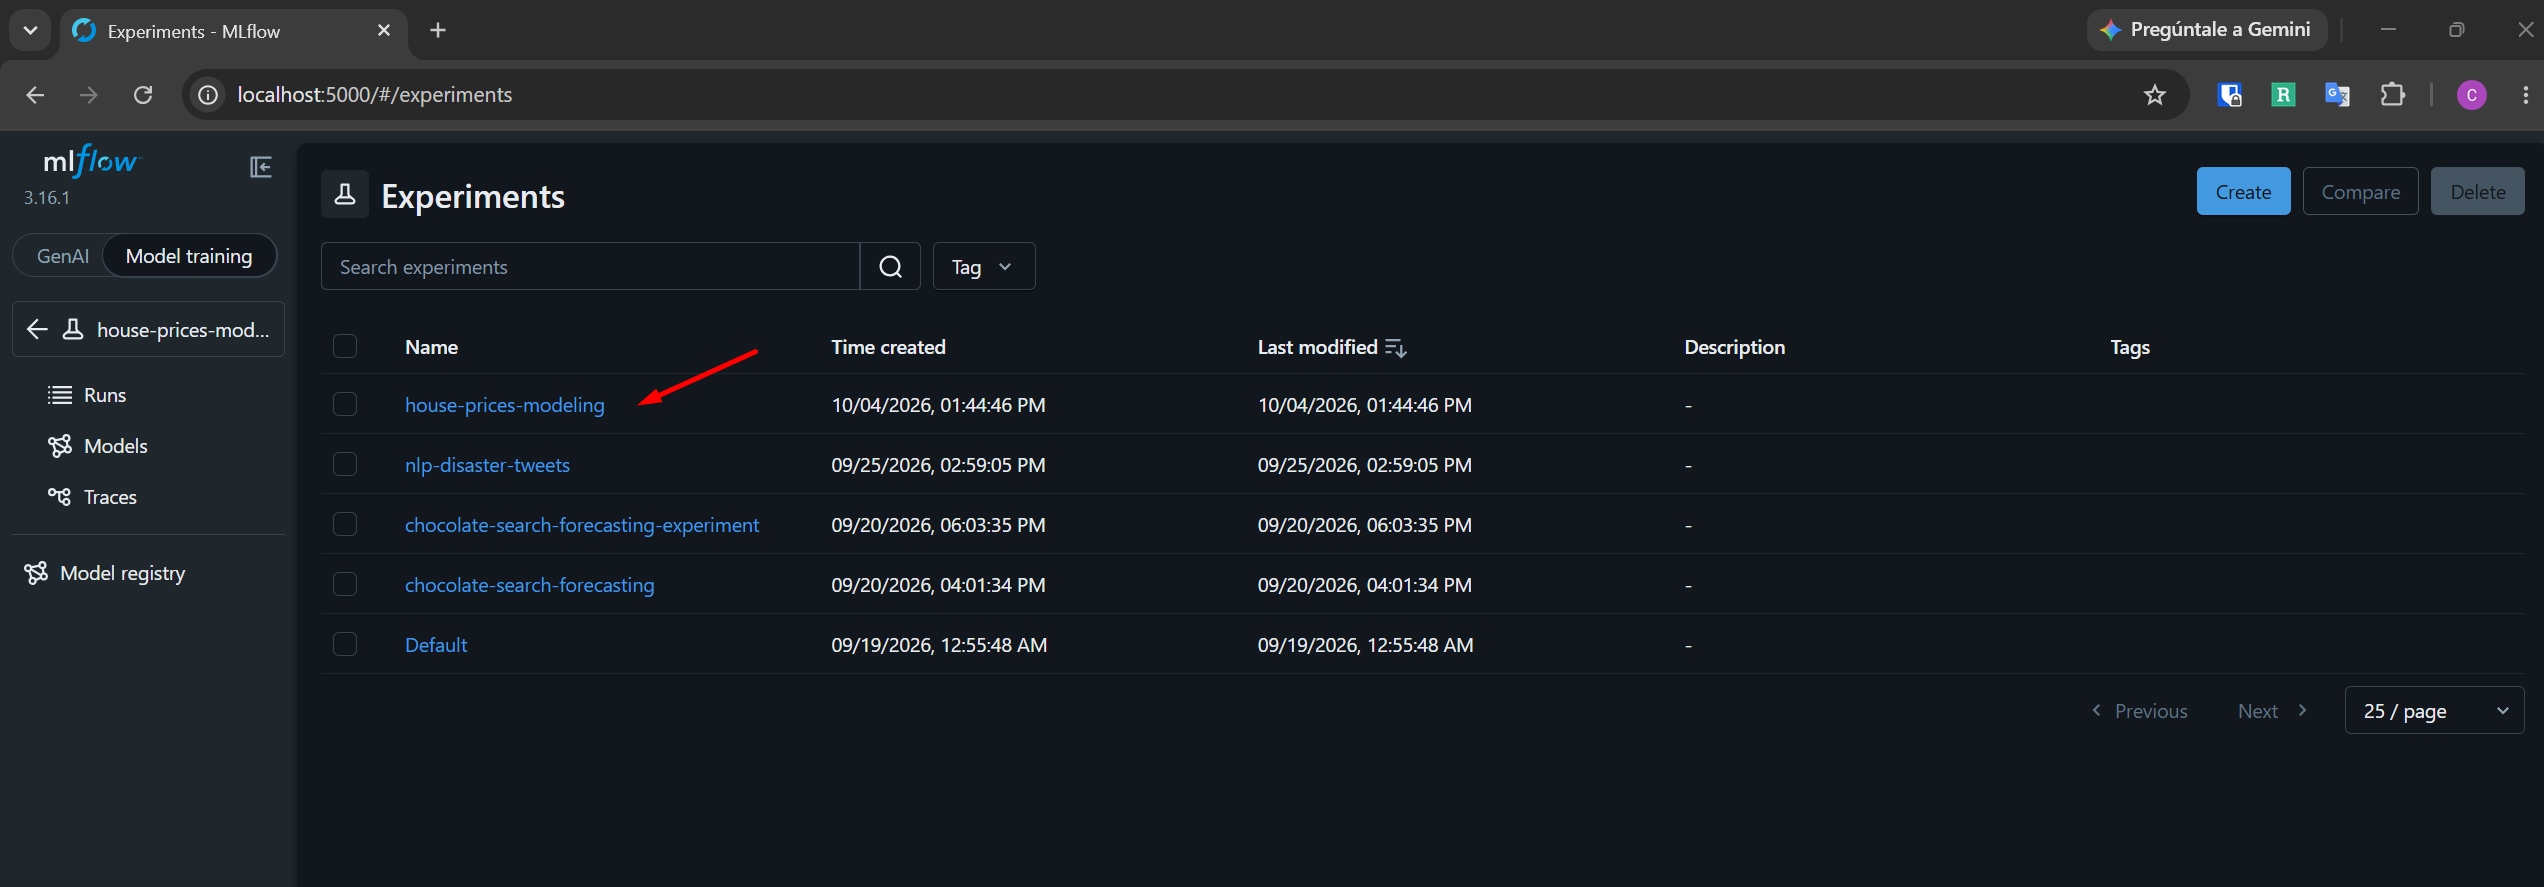

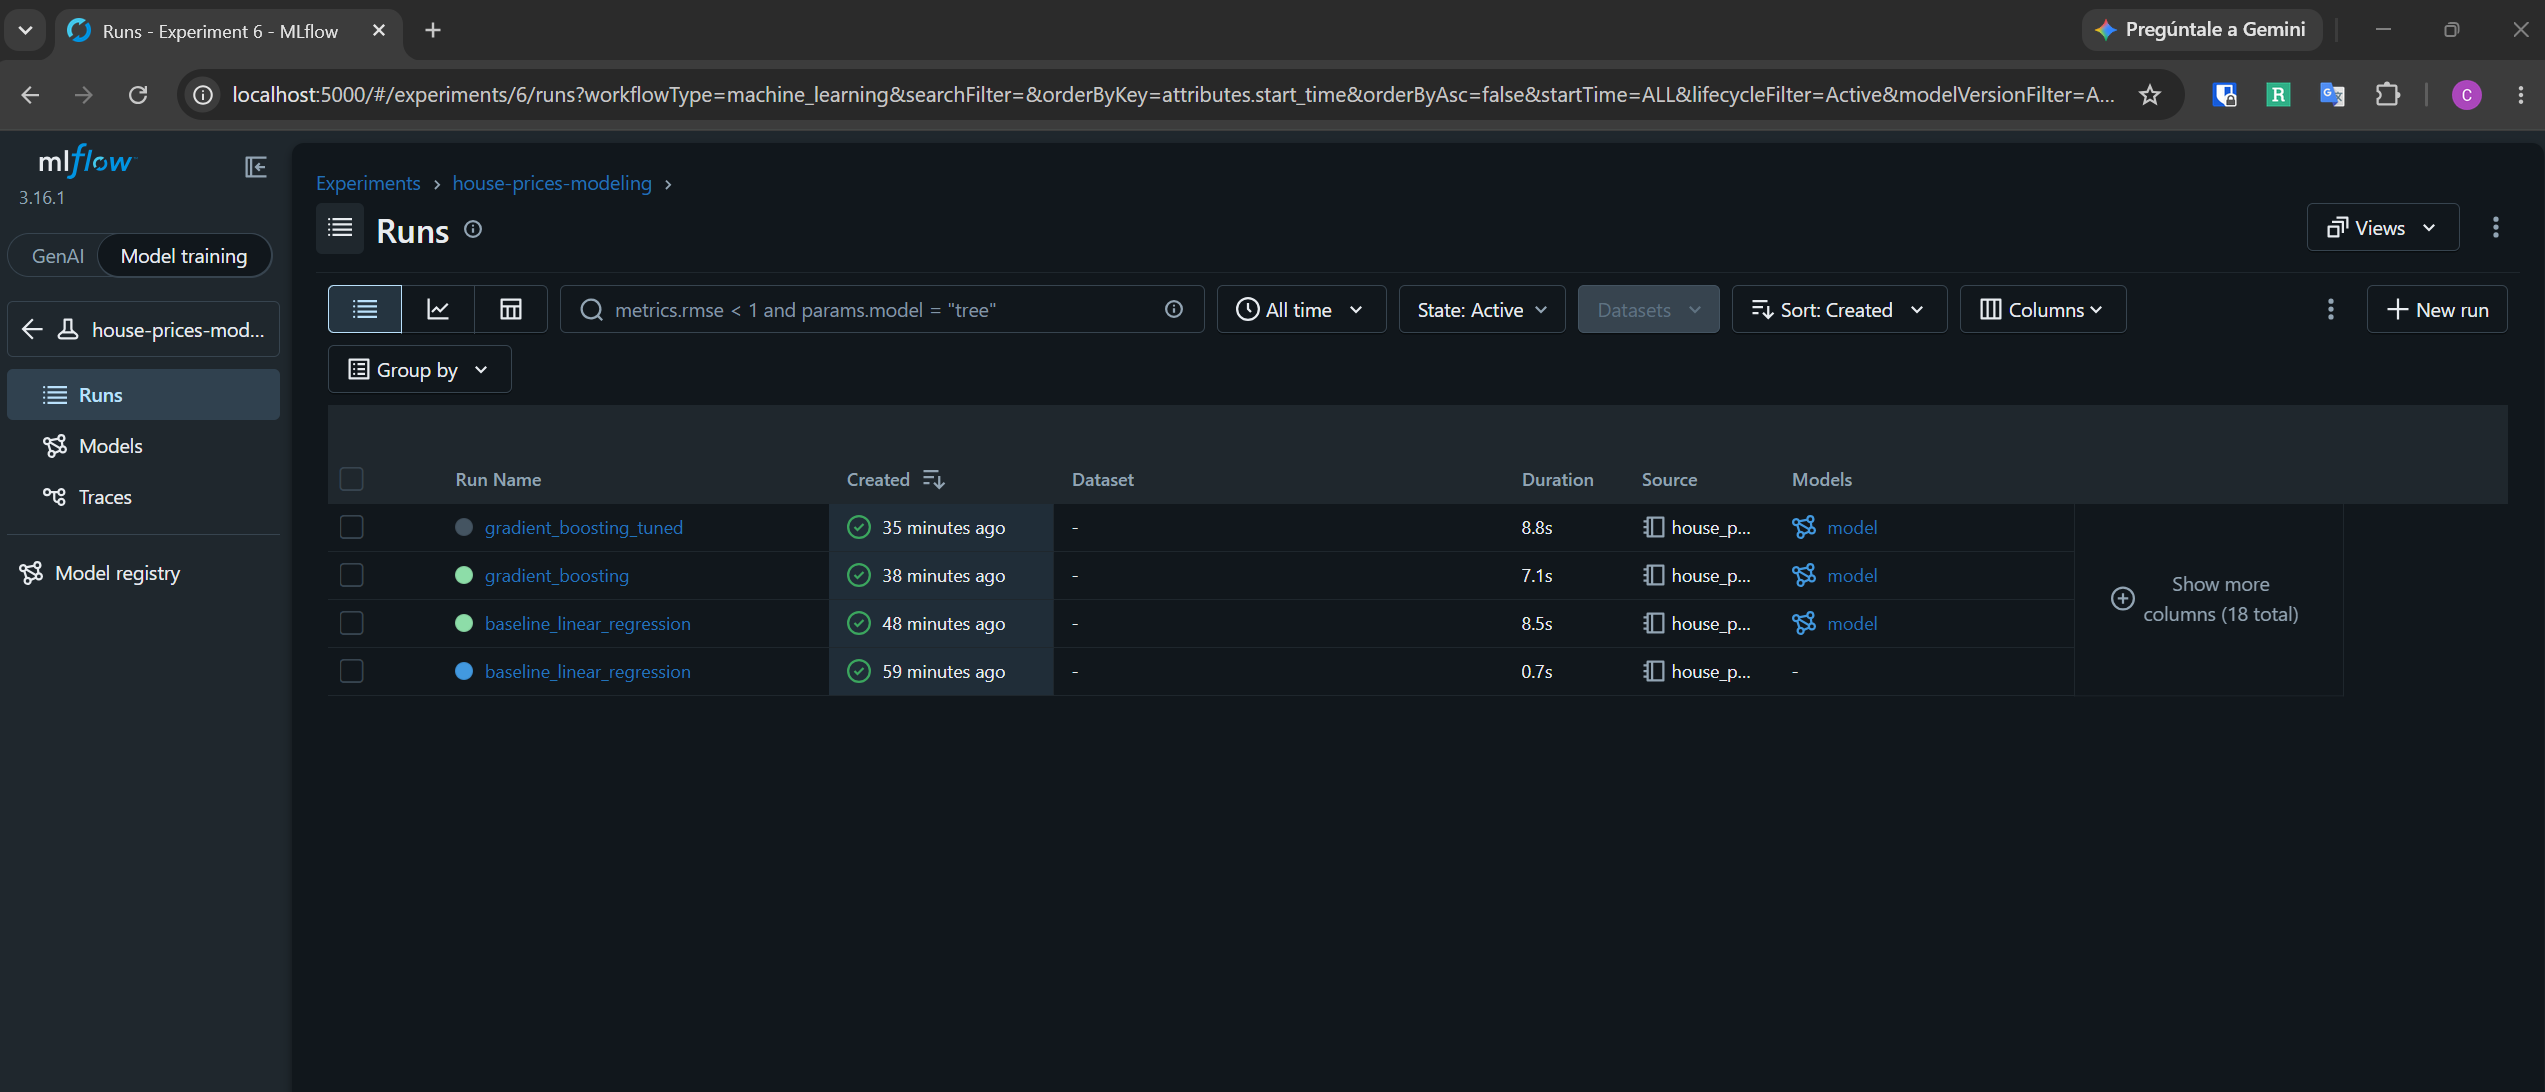
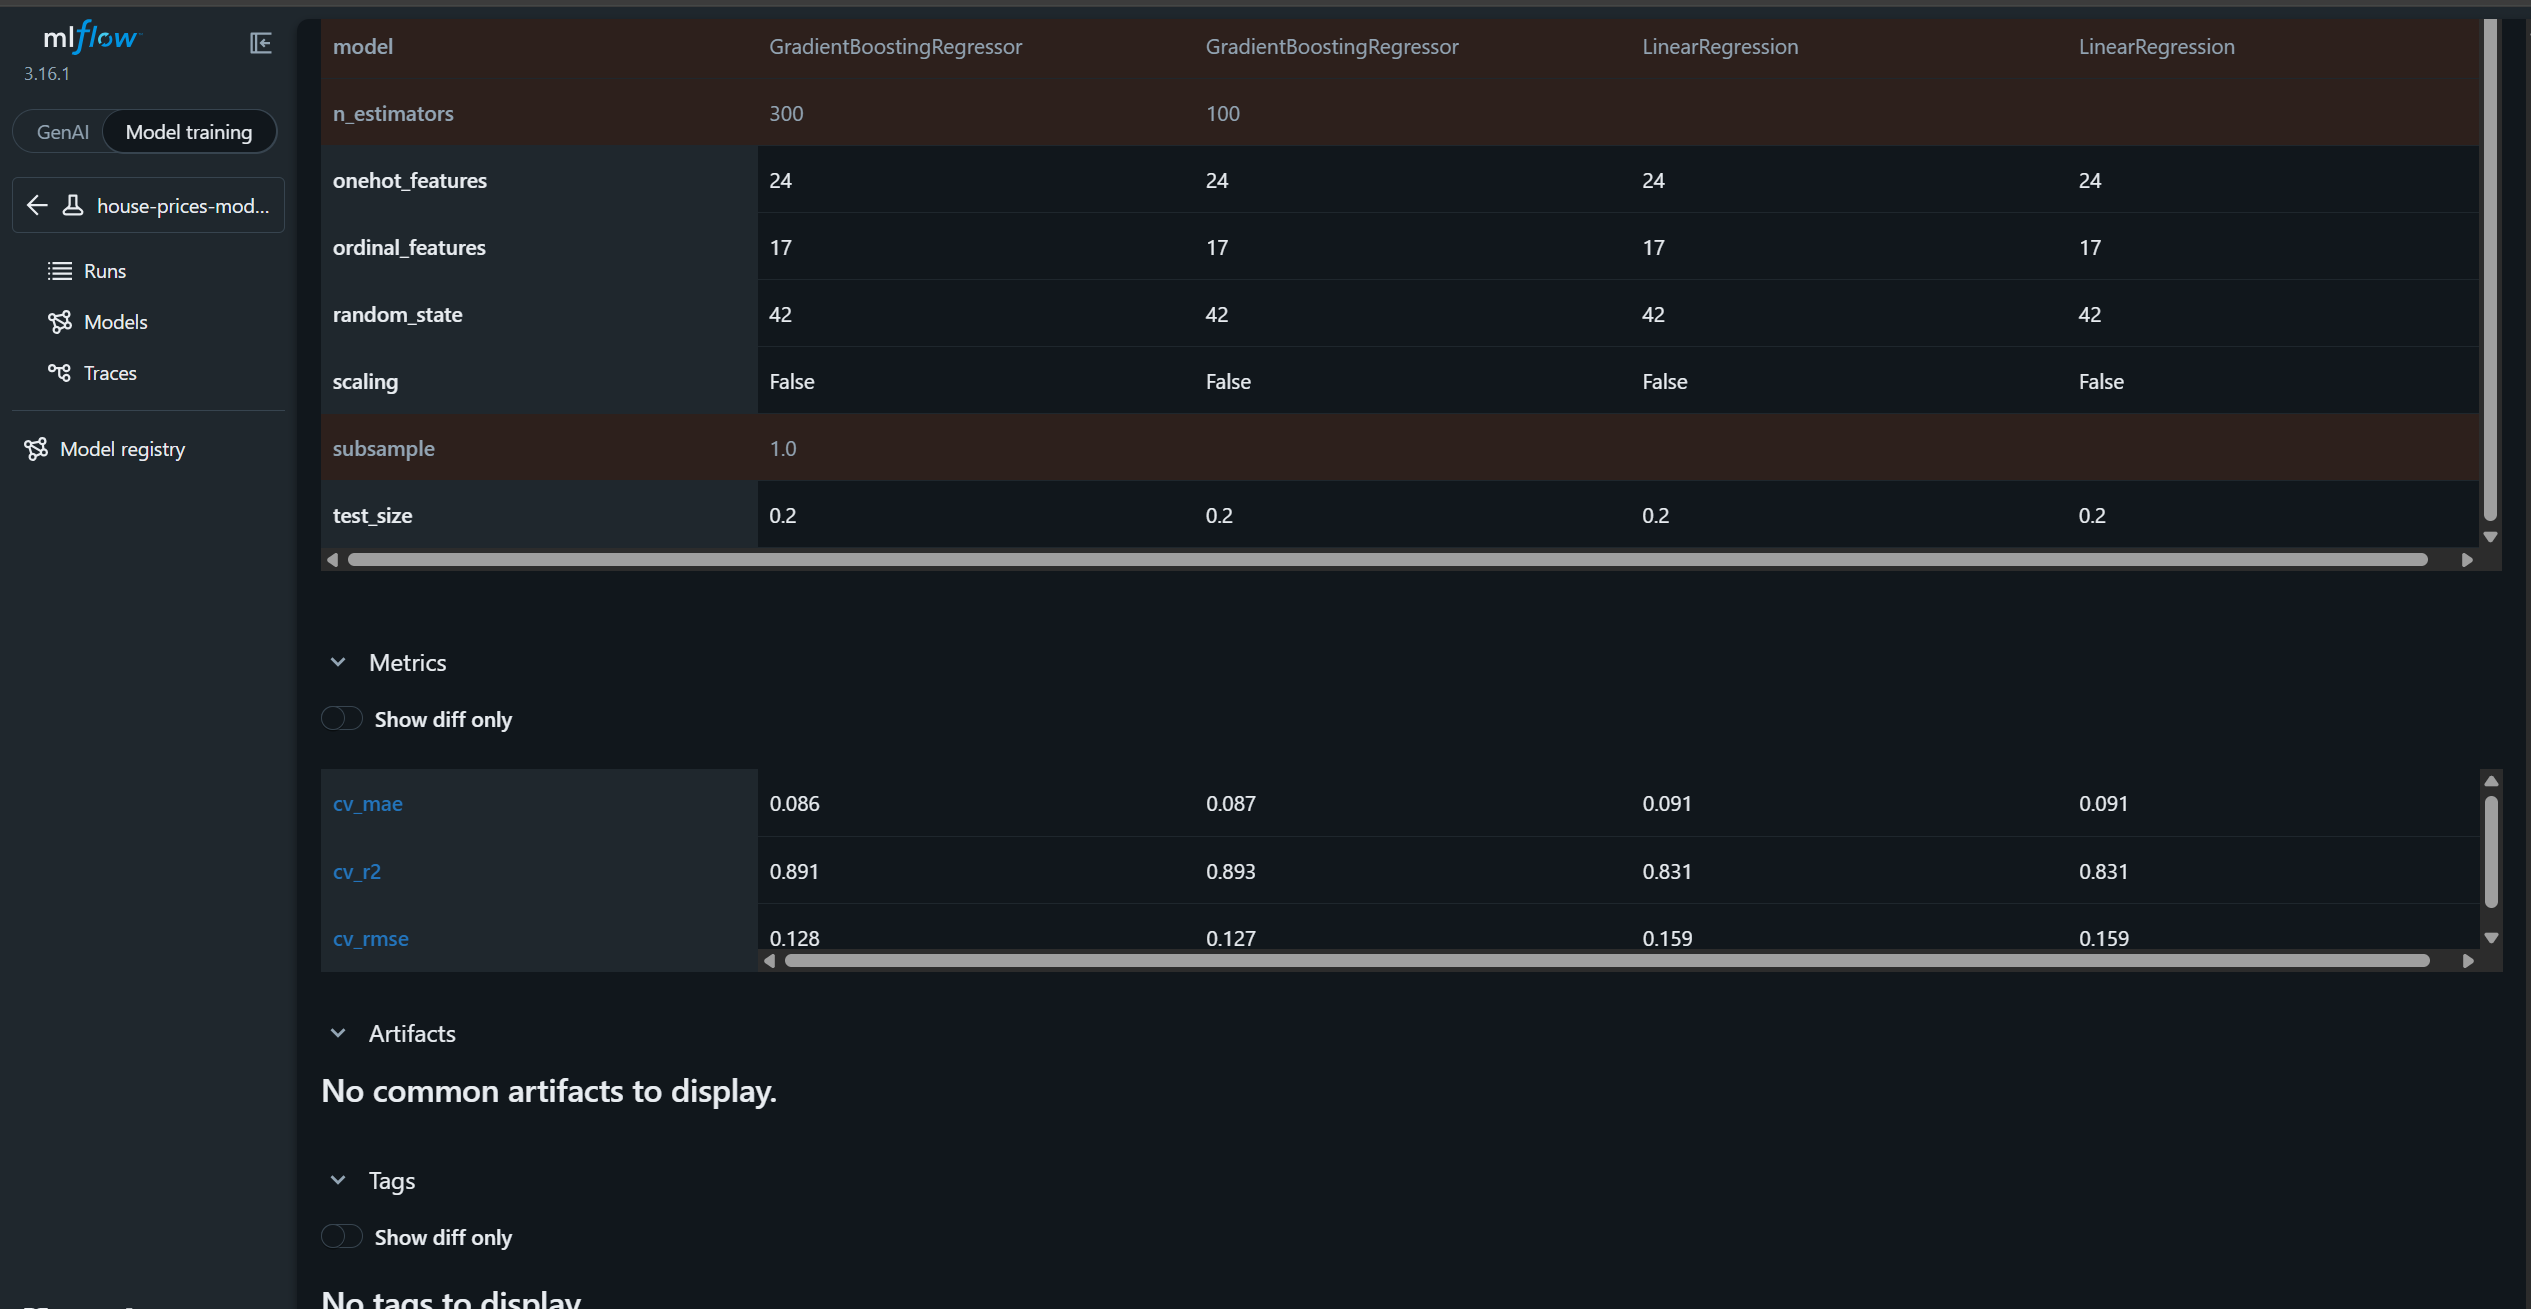

## 7. Reflexión

Este ejercicio me permitió entender que desarrollar un modelo de Machine Learning no consiste únicamente en obtener buenas métricas, sino en construir un proceso que pueda ser entendido, reproducido y mejorado. Una de las principales áreas que mejoraría mediante prácticas de MLOps es la trazabilidad entre las etapas de Data Understanding, Data Preparation y Modeling. Durante el análisis se toman muchas decisiones sobre valores faltantes, tipos de variables, transformaciones, selección de características y estrategias de codificación. Si estas decisiones no se registran adecuadamente, es fácil perder el contexto de por qué se realizó una modificación o incluso dejar transformaciones pendientes.

También considero fundamental automatizar las validaciones entre etapas. Por ejemplo, antes de comenzar el modelado deberían existir controles que aseguren que no quedan valores faltantes, variables categóricas sin estrategia de codificación, inconsistencias o decisiones pendientes. De esta manera, los errores se detectarían antes de llegar al entrenamiento del modelo.

El uso de MLflow también mostró la importancia de registrar no solamente las métricas finales, sino los parámetros, el preprocesamiento y el modelo asociado a cada experimento. Esto permite comparar ejecuciones y entender exactamente qué configuración produjo cada resultado, en lugar de depender únicamente de notebooks o resultados aislados.

Dentro de mi área profesional, estos aprendizajes son especialmente relevantes para el desarrollo de soluciones de software e inteligencia artificial que deben evolucionar con el tiempo. Un modelo puede funcionar correctamente durante un experimento, pero llevarlo a un entorno real requiere procesos reproducibles, versionados, monitoreables y automatizados. Por ello, considero que MLOps funciona como el vínculo entre la experimentación de Machine Learning y la construcción de sistemas de IA confiables y mantenibles.